In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/leukipp/reddit-finance-data/finance/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/finance/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/gme/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/gme/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/pennystocks/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/pennystocks/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/options/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/options/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/stocks/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/stocks/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/forex/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/forex/submissions_reddit.csv
/kaggle/input/datasets/leuki

In [2]:
#   Session 0: SESSION=0 → qwen2_05b   (full_lora)
#   Session 1: SESSION=1 → qwen2_15b   (attn_only)
#   Session 2: SESSION=2 → llama32_1b  (ffn_only)
#   Session 3: SESSION=3 → llama32_3b  (qlora_4bit)
#   Session 4: SESSION=4 → gemma2_2b   (qlora_low_r)
#   Session 5: SESSION=5 → phi3_mini   (dora)
#   Session 6: SESSION=6 → tinyllama   (high_rank)

In [3]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SET THESE TWO VARIABLES BEFORE EACH KAGGLE RUN                        ║
# ╚══════════════════════════════════════════════════════════════════════════╝
SESSION_MODEL = 2         # 0=qwen2_05b 1=qwen2_15b 2=llama32_1b 3=llama32_3b
                           # 4=gemma2_2b 5=phi3_mini  6=tinyllama
SESSION_STRAT = 'flora'    # 'flora' | 'fedavg' | 'all'

In [4]:

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 1 — Install                                                      ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import os, sys
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_ENABLE_HF_TRANSFER'] = '0'

get_ipython().system(
    'pip install -q unsloth codecarbon datasets transformers peft trl '
    'accelerate bitsandbytes scikit-learn scipy matplotlib seaborn '
    'sentencepiece protobuf rouge-score bert-score Faker')
get_ipython().system('pip uninstall -q -y codecarbon')
get_ipython().system('pip install -q codecarbon==2.3.4')
# ADD after your existing pip install line:
get_ipython().system('pip install -q spacy')
get_ipython().system('python -m spacy download en_core_web_sm -q')
import torch
print(f'CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU : {props.name}  VRAM: {props.total_memory/1e9:.1f} GB')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.6/384.6 kB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 121.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [5]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 2 — Config                                                       ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import copy, random, warnings, pickle, gc
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)

WORKDIR    = '/kaggle/working'
CLIENT_DIR = os.path.join(WORKDIR, 'federated_clients')
OUTPUT_DIR = os.path.join(WORKDIR, 'greenfed_output')
os.makedirs(CLIENT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

NUM_CLASSES = 6
LABEL2INT   = {'credit_card_billing':0,'mortgage_loan':1,'debt_collection':2,
               'bank_account':3,'credit_reporting':4,'money_transfer_fraud':5}
INT2LABEL   = {v:k for k,v in LABEL2INT.items()}
CLASS_NAMES = [INT2LABEL[i] for i in range(NUM_CLASSES)]

# ── Critical timing parameters ────────────────────────────────────────────
NUM_CLIENTS            = 50
NUM_ROUNDS             = 5      # ← reduced from 10 to stay under 9hr limit

# ── Option C training parameters ─────────────────────────────────────────
MAX_SAMPLES_PER_CLIENT = 500    # ← up from 150; real non-IID exploitation
MAX_STEPS_PER_CLIENT   = 100    # ← up from 50; meaningful weight updates
BATCH_SIZE             = 8      # unchanged
GA_STEPS               = 4      # ← up from 2; effective batch = 32
LOCAL_LR               = 2e-4   # unchanged
MAX_SEQ_LEN            = 256    # unchanged
LOCAL_EPOCHS           = 1      # SFTConfig uses max_steps anyway
MAX_CFPB_ROWS = 100_000   # cap before NER to stay within 9hr limit
# CLIENTS_PER_ROUND: 10 for flora/fedavg (thesis spec), 10 for 'all'
CLIENTS_PER_ROUND_UTIL = 10     # ← up from 5; matches thesis top-10
CLIENTS_PER_ROUND_ALL  = 10     # cap for 'all' strategy

EVAL_SUBSET    = 60
EVAL_BATCH_SZ  = 8
MAX_NEW_TOKENS = 80

GHOST_CLASS_MIN    = 2
MIN_AGG_SAMPLES    = 5
BATTERY_DEPLETION  = 0.03
PART_PENALTY       = 0.005
BERTSCORE_MODEL    = 'distilbert-base-uncased'

STRAT_STYLES = {
    'flora' :{'label':'GreenFed-LoRA (FLoRA)','color':'#2ecc71','ls':'-', 'marker':'s'},
    'fedavg':{'label':'FedAvg Baseline',      'color':'#e74c3c','ls':'--','marker':'o'},
    'all'   :{'label':'All Clients (FLoRA)',  'color':'#3498db','ls':'-.','marker':'^'},
}

# ── Structured response templates ─────────────────────────────────────────
RESPONSE_TEMPLATES = {
    0:("Issue Type: Credit Card Billing Dispute | Severity: High | "
       "What Went Wrong: Unauthorized or incorrect charge on credit card. | "
       "Recommended Action: Dispute charge with issuer, request chargeback."),
    1:("Issue Type: Mortgage or Loan Problem | Severity: High | "
       "What Went Wrong: Issues with mortgage servicing or payment processing. | "
       "Recommended Action: File QWR under RESPA, escalate to CFPB if unresolved."),
    2:("Issue Type: Debt Collection Harassment | Severity: Critical | "
       "What Went Wrong: Abusive or illegal debt collection practices. | "
       "Recommended Action: Send cease-and-desist, file FDCPA complaint with FTC."),
    3:("Issue Type: Bank Account Service Failure | Severity: Medium | "
       "What Went Wrong: Unauthorized transactions or unexplained account freeze. | "
       "Recommended Action: Freeze account immediately, dispute under Regulation E."),
    4:("Issue Type: Credit Reporting Error | Severity: High | "
       "What Went Wrong: Inaccurate or fraudulent credit report entries. | "
       "Recommended Action: File FCRA dispute with credit bureau, request correction."),
    5:("Issue Type: Money Transfer Fraud | Severity: Critical | "
       "What Went Wrong: Failed or fraudulent wire transfer or digital payment. | "
       "Recommended Action: Report to institution, file FTC fraud claim immediately."),
}

# ── Model Registry ─────────────────────────────────────────────────────────
MODEL_REGISTRY = [
    dict(session_key='qwen2_05b',  display='Qwen2-0.5B',    finetune='full_lora',
         model_path='unsloth/Qwen2-0.5B-Instruct',
         lora_r=8, lora_alpha=16, lora_dropout=0.0, use_dora=False,
         lora_targets=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj']),
    dict(session_key='qwen2_15b',  display='Qwen2-1.5B',    finetune='attn_only',
         model_path='unsloth/Qwen2-1.5B-Instruct',
         lora_r=8, lora_alpha=16, lora_dropout=0.0, use_dora=False,
         lora_targets=['q_proj','k_proj','v_proj','o_proj']),
    dict(session_key='llama32_1b', display='Llama-3.2-1B',  finetune='ffn_only',
         model_path='unsloth/Llama-3.2-1B-Instruct',
         lora_r=8, lora_alpha=16, lora_dropout=0.0, use_dora=False,
         lora_targets=['gate_proj','up_proj','down_proj']),
    dict(session_key='llama32_3b', display='Llama-3.2-3B',  finetune='qlora_4bit',
         model_path='unsloth/Llama-3.2-3B-Instruct',
         lora_r=8, lora_alpha=16, lora_dropout=0.0, use_dora=False,
         lora_targets=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj']),
    dict(session_key='gemma2_2b',  display='Gemma-2-2B',    finetune='qlora_low_r',
         model_path='unsloth/gemma-2-2b-it',
         lora_r=4, lora_alpha=8,  lora_dropout=0.0, use_dora=False,
         lora_targets=['q_proj','k_proj','v_proj','o_proj']),
    dict(session_key='phi3_mini',  display='Phi-3-mini',     finetune='dora',
         model_path='unsloth/Phi-3-mini-4k-instruct',
         lora_r=8, lora_alpha=16, lora_dropout=0.0, use_dora=True,
         lora_targets=['qkv_proj','o_proj','gate_up_proj']),
    dict(session_key='tinyllama',  display='TinyLlama-1.1B', finetune='high_rank',
         model_path='unsloth/tinyllama-chat',
         lora_r=16, lora_alpha=32, lora_dropout=0.05, use_dora=False,
         lora_targets=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj']),
]

ACTIVE_CFG   = MODEL_REGISTRY[SESSION_MODEL]
ACTIVE_STRAT = SESSION_STRAT
N_SEL = CLIENTS_PER_ROUND_ALL if ACTIVE_STRAT == 'all' else CLIENTS_PER_ROUND_UTIL
# ── Two-Stage Privacy Pipeline Config ─────────────────────────────────────
# Stage 1: NER de-identification source control
USE_REDDIT   = True    # True = load r/PersonalFinance + CFPB; False = CFPB only
REDDIT_ROWS  = 80_000  # how many Reddit posts to pull (keeps build time reasonable)

# NER entity types to anonymise → placeholder token
NER_REPLACEMENTS = {
    'PERSON':   '[PERSON]',
    'GPE':      '[LOCATION]',
    'LOC':      '[LOCATION]',
    'ORG':      '[ORG]',       # keep this — financial institution names are not PII
    'MONEY':    '[AMOUNT]',
    'DATE':     '[DATE]',
    'TIME':     '[DATE]',
    'CARDINAL': '[NUMBER]',
    'ORDINAL':  '[NUMBER]',
}
# Note: deliberately NOT anonymising ORG — "Chase charged me" is fine;
# the institution name is not the user's private data.
# Swap to '[ORG]' if you want stricter anonymisation for the thesis argument.
# ── Time estimate (Option C) ──────────────────────────────────────────────
# 100 steps × ~4s/step (larger effective batch slows slightly vs 50×3s)
# + evaluation overhead per round (~4 min with EVAL_SUBSET=60)
secs_per_client  = MAX_STEPS_PER_CLIENT * 4
total_clients    = N_SEL * NUM_ROUNDS
eval_secs        = NUM_ROUNDS * 240   # ~4 min eval per round
est_hrs          = (total_clients * secs_per_client + eval_secs) / 3600

print(f'\n{"═"*58}')
print(f'  Model        : {ACTIVE_CFG["display"]} ({ACTIVE_CFG["finetune"]})')
print(f'  Strategy     : {ACTIVE_STRAT}')
print(f'  Clients/round: {N_SEL} × {NUM_ROUNDS} rounds = {total_clients} total')
print(f'  Steps/client : {MAX_STEPS_PER_CLIENT} | Eff. batch: {BATCH_SIZE*GA_STEPS}')
print(f'  Samples/client: {MAX_SAMPLES_PER_CLIENT}')
print(f'  Estimated time: {est_hrs:.1f} hours')
if est_hrs > 8.5:
    print(f'  ⚠ WARNING: Exceeds 9hr limit! Reduce NUM_ROUNDS or N_SEL.')
else:
    print(f'  ✅ Safe for Kaggle 9hr limit')
print(f'{"═"*58}')


══════════════════════════════════════════════════════════
  Model        : Llama-3.2-1B (ffn_only)
  Strategy     : flora
  Clients/round: 10 × 5 rounds = 50 total
  Steps/client : 100 | Eff. batch: 32
  Samples/client: 500
  Estimated time: 5.9 hours
  ✅ Safe for Kaggle 9hr limit
══════════════════════════════════════════════════════════


In [6]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files[:5]:
        print(os.path.join(root, f))

/kaggle/input/datasets/leukipp/reddit-finance-data/finance/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/finance/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/gme/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/gme/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/pennystocks/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/pennystocks/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/options/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/options/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/stocks/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/stocks/submissions_reddit.csv
/kaggle/input/datasets/leukipp/reddit-finance-data/forex/submissions_reddit.h5
/kaggle/input/datasets/leukipp/reddit-finance-data/forex/submissions_reddit.csv
/kaggle/input/datasets/leuki

In [7]:
reddit_raw = pd.read_csv(
    "/kaggle/input/datasets/leukipp/reddit-finance-data/finance/submissions_reddit.csv"
)

print(reddit_raw.head())
print(reddit_raw.columns)

       id           author              created            retrieved  \
0  ko3ecd         bighlovd  2021-01-01 02:33:23  2021-02-04 06:28:30   
1  ko4jed   naturalhighguy  2021-01-01 03:56:40  2021-02-04 06:28:30   
2  ko65fk        Venky2310  2021-01-01 05:55:12  2021-02-04 06:28:30   
3  koaw8g        [deleted]  2021-01-01 12:57:48  2021-02-04 06:28:30   
4  kobbka  fintechinshorts  2021-01-01 13:31:53  2021-02-04 06:28:30   

                edited  pinned  archived  locked  removed  deleted  ...  \
0  1970-01-01 00:00:00       0         0       0        1        0  ...   
1  1970-01-01 00:00:00       0         0       0        1        0  ...   
2  1970-01-01 00:00:00       0         0       0        1        0  ...   
3  1970-01-01 00:00:00       0         0       0        1        1  ...   
4  1970-01-01 00:00:00       0         0       0        1        0  ...   

   link_flair_text  upvote_ratio  score gilded  total_awards_received  \
0              NaN          0.50      0    

In [8]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 3 — Two-Stage Privacy Pipeline: Load + NER-Anonymise + Split     ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import re, spacy
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from tqdm import tqdm

print('Loading spaCy NER model...')
nlp = spacy.load('en_core_web_sm')
nlp.max_length = 1_500_000
print('  spaCy ready.')

# ── Stage 1A: NER de-identification ───────────────────────────────────────
def anonymise(text: str):
    if not isinstance(text, str):
        return None
    text = re.sub(r'XX+/XX+/XXXX', '[DATE]', text)
    text = re.sub(r'XXXX+', '[REDACTED]', text)
    text = re.sub(r'\s+', ' ', text).strip()
    if len(text.split()) < 20:
        return None
    text_for_ner = ' '.join(text.split()[:300])
    doc = nlp(text_for_ner)
    result = text_for_ner
    for ent in reversed(doc.ents):
        replacement = NER_REPLACEMENTS.get(ent.label_)
        if replacement:
            result = result[:ent.start_char] + replacement + result[ent.end_char:]
    result = re.sub(r'\s+', ' ', result).strip()
    return result if len(result.split()) >= 15 else None

# ── Stage 1B: Category mapping ────────────────────────────────────────────
CATEGORY_MAP = {
    'Credit card':                       'credit_card_billing',
    'Credit card or prepaid card':       'credit_card_billing',
    'Prepaid card':                      'credit_card_billing',
    'Mortgage':                          'mortgage_loan',
    'Student loan':                      'mortgage_loan',
    'Payday loan':                       'mortgage_loan',
    'Payday loan, title loan, or personal loan': 'mortgage_loan',
    'Vehicle loan or lease':             'mortgage_loan',
    'Debt collection':                   'debt_collection',
    'Bank account or service':           'bank_account',
    'Checking or savings account':       'bank_account',
    'Credit reporting':                  'credit_reporting',
    'Credit reporting, credit repair services, or other personal consumer reports':
                                         'credit_reporting',
    'Money transfer, virtual currency, or money service': 'money_transfer_fraud',
    'Money transfers':                   'money_transfer_fraud',
    'Other financial service':           'money_transfer_fraud',
}

REDDIT_CATEGORY_MAP = {
    'Credit Cards':   'credit_card_billing',
    'credit cards':   'credit_card_billing',
    'Loans':          'mortgage_loan',
    'Student Loans':  'mortgage_loan',
    'Auto':           'mortgage_loan',
    'Housing':        'mortgage_loan',
    'mortgage':       'mortgage_loan',
    'Debt':           'debt_collection',
    'debt':           'debt_collection',
    'Collections':    'debt_collection',
    'Banking':        'bank_account',
    'banking':        'bank_account',
    'Budgeting':      'bank_account',
    'Credit Score':   'credit_reporting',
    'Credit':         'credit_reporting',
    'credit':         'credit_reporting',
    'Investing':      'money_transfer_fraud',
    'Scams':          'money_transfer_fraud',
    'fraud':          'money_transfer_fraud',
    'Insurance':      'money_transfer_fraud',
}

TRAIN_CSV = os.path.join(WORKDIR, 'cfpb_train.csv')
TEST_CSV  = os.path.join(WORKDIR, 'cfpb_test.csv')
INST_CSV  = os.path.join(WORKDIR, 'institution_profiles.csv')
STATS_CSV = os.path.join(WORKDIR, 'client_stats.csv')
ANON_LOG  = os.path.join(WORKDIR, 'anonymisation_log.json')

DATA_READY = (os.path.exists(TRAIN_CSV) and os.path.exists(TEST_CSV)
              and os.path.exists(INST_CSV) and os.path.exists(STATS_CSV)
              and len(os.listdir(CLIENT_DIR)) >= NUM_CLIENTS)

if DATA_READY:
    print('Data already built — loading from disk...')
    df_train = pd.read_csv(TRAIN_CSV)
    df_test  = pd.read_csv(TEST_CSV)
    inst_df  = pd.read_csv(INST_CSV)
    stats_df = pd.read_csv(STATS_CSV)
    stats_df['adjusted_utility'] = stats_df['utility_score']
    print(f'Train:{len(df_train):,} Test:{len(df_test):,} Clients:{len(stats_df)}')

else:
    print('Building two-stage privacy pipeline from scratch...')
    frames_raw = []

    # ── Load CFPB (capped at MAX_CFPB_ROWS before NER) ────────────────────
    print('\n[Stage 1] Loading CFPB Consumer Complaints...')
    df_raw = None
    for ds_name in ['CFPB/consumer-finance-complaints',
                    '23daVinci/CFPB_Complaints']:
        try:
            df_raw = load_dataset(ds_name, split='train').to_pandas()
            print(f'  Loaded {ds_name}: {len(df_raw):,} rows')
            break
        except Exception as e:
            print(f'  Failed {ds_name}: {e}')

    if df_raw is not None:
        tc = next((c for c in ['Consumer complaint narrative',
                                'consumer_complaint_narrative',
                                'narrative', 'text']
                   if c in df_raw.columns), None)
        pc = next((c for c in ['Product', 'product'] if c in df_raw.columns), None)
        if tc and pc:
            sub = df_raw[[tc, pc]].copy()
            sub.columns = ['text', 'product']
            sub['category'] = sub['product'].map(CATEGORY_MAP)
            sub = sub.dropna(subset=['category'])
            # ── KEY FIX: cap before NER ────────────────────────────────────
            if len(sub) > MAX_CFPB_ROWS:
                sub = (sub.groupby('category', group_keys=False)
                          .apply(lambda g: g.sample(
                              min(len(g),
                                  MAX_CFPB_ROWS * len(g) // len(sub) + 1),
                              random_state=42))
                          .sample(frac=1, random_state=42)
                          .reset_index(drop=True)
                          .iloc[:MAX_CFPB_ROWS])
                print(f'  CFPB sampled to {MAX_CFPB_ROWS:,} rows '
                      f'(stratified by category)')
            sub['source'] = 'cfpb'
            frames_raw.append(sub[['text', 'category', 'source']])
            print(f'  CFPB usable rows: {len(sub):,}')

    # ── Load Reddit from Kaggle dataset ───────────────────────────────────
    # Primary source: /kaggle/input/datasets/leukipp/reddit-finance-data
    # Falls back cleanly to CFPB-only if path or columns are missing.
    if USE_REDDIT:
        print('\n[Stage 1] Loading Reddit Finance Dataset (Kaggle)...')
        REDDIT_KAGGLE_PATH = '/kaggle/input/datasets/leukipp/reddit-finance-data'

        try:
            # Find CSV automatically (handles any subdirectory structure)
            csv_files = []
            for root, dirs, files in os.walk(REDDIT_KAGGLE_PATH):
                for f in files:
                    if f.endswith('.csv'):
                        csv_files.append(os.path.join(root, f))

            if not csv_files:
                raise FileNotFoundError(
                    f'No CSV found under {REDDIT_KAGGLE_PATH}')

            # Pick the largest CSV if there are multiple
            csv_path = max(csv_files, key=os.path.getsize)
            print(f'  Using: {csv_path}  '
                  f'({os.path.getsize(csv_path)/1e6:.1f} MB)')

            reddit_raw = pd.read_csv(csv_path, low_memory=False)
            print(f'  Loaded: {len(reddit_raw):,} rows | '
                  f'columns: {reddit_raw.columns.tolist()}')

            # Detect text column
            text_col = next(
                (c for c in ['selftext', 'body', 'text', 'content',
                              'post', 'title']
                 if c in reddit_raw.columns), None)

            # Detect flair/category column
            flair_col = next(
                (c for c in ['link_flair_text', 'flair',
                              'category', 'tag', 'subreddit']
                 if c in reddit_raw.columns), None)

            if text_col is None:
                raise ValueError(
                    f'No usable text column found. '
                    f'Available: {reddit_raw.columns.tolist()}')

            print(f'  Text column: "{text_col}" | '
                  f'Flair column: "{flair_col}"')

            # Cap before NER (already set in Block 2 via REDDIT_ROWS)
            if len(reddit_raw) > REDDIT_ROWS:
                reddit_raw = reddit_raw.sample(
                    REDDIT_ROWS, random_state=42).reset_index(drop=True)
                print(f'  Sampled to {REDDIT_ROWS:,} rows')

            reddit_sub = reddit_raw[[text_col]].copy()
            reddit_sub.columns = ['text']

            # Category assignment: flair mapping first, keyword fallback
            if flair_col:
                reddit_sub['category'] = (
                    reddit_raw[flair_col]
                    .astype(str)
                    .map(REDDIT_CATEGORY_MAP))
                mapped = reddit_sub['category'].notna().sum()
                print(f'  Flair-mapped: {mapped:,} rows')

                # Keyword fallback for rows where flair didn't match
                unmapped_mask = reddit_sub['category'].isna()
                if unmapped_mask.sum() > 0:
                    def keyword_category(t):
                        if not isinstance(t, str):
                            return None
                        t = t.lower()
                        if any(w in t for w in ['credit card', 'billing',
                                                 'charged twice']):
                            return 'credit_card_billing'
                        if any(w in t for w in ['mortgage', 'student loan',
                                                 'auto loan']):
                            return 'mortgage_loan'
                        if any(w in t for w in ['debt', 'collection',
                                                 'collector']):
                            return 'debt_collection'
                        if any(w in t for w in ['bank account', 'checking',
                                                 'savings']):
                            return 'bank_account'
                        if any(w in t for w in ['credit score',
                                                 'credit report']):
                            return 'credit_reporting'
                        if any(w in t for w in ['fraud', 'scam',
                                                 'wire transfer']):
                            return 'money_transfer_fraud'
                        return None
                    reddit_sub.loc[unmapped_mask, 'category'] = (
                        reddit_sub.loc[unmapped_mask, 'text']
                        .apply(keyword_category))
                    kw_matched = (reddit_sub.loc[unmapped_mask, 'category']
                                  .notna().sum())
                    print(f'  Keyword fallback added: {kw_matched:,} more rows')
            else:
                # No flair column at all — pure keyword classification
                def keyword_category(t):
                    if not isinstance(t, str):
                        return None
                    t = t.lower()
                    if any(w in t for w in ['credit card', 'billing',
                                             'charged twice']):
                        return 'credit_card_billing'
                    if any(w in t for w in ['mortgage', 'student loan',
                                             'auto loan']):
                        return 'mortgage_loan'
                    if any(w in t for w in ['debt', 'collection',
                                             'collector']):
                        return 'debt_collection'
                    if any(w in t for w in ['bank account', 'checking',
                                             'savings']):
                        return 'bank_account'
                    if any(w in t for w in ['credit score', 'credit report']):
                        return 'credit_reporting'
                    if any(w in t for w in ['fraud', 'scam', 'wire transfer']):
                        return 'money_transfer_fraud'
                    return None
                reddit_sub['category'] = reddit_sub['text'].apply(
                    keyword_category)

            reddit_sub = reddit_sub.dropna(subset=['category'])
            reddit_sub['source'] = 'reddit'
            frames_raw.append(reddit_sub[['text', 'category', 'source']])
            print(f'  Reddit usable rows after category filter: '
                  f'{len(reddit_sub):,}')

        except Exception as e:
            print(f'  Reddit load error: {e}')
            print('  Continuing with CFPB only.')

    # ── Combine sources ────────────────────────────────────────────────────
    df_combined = pd.concat(frames_raw, ignore_index=True)
    print(f'\n  Combined raw rows: {len(df_combined):,}')
    print(f'  Sources: {df_combined["source"].value_counts().to_dict()}')
    print(f'  Classes: {df_combined["category"].value_counts().to_dict()}')

    # ── Stage 1 NER Anonymisation ──────────────────────────────────────────
    # With MAX_CFPB_ROWS=100k + REDDIT_ROWS=50k this is ~150k rows max.
    # At ~300 words/doc and 5000 docs/chunk: ~5–12 min total.
    print(f'\n[Stage 1] Applying NER de-identification to '
          f'{len(df_combined):,} rows...')
    print('  Estimated time: 5–12 minutes.')

    CHUNK = 5000
    anon_texts = []
    n_total = len(df_combined)

    for start in range(0, n_total, CHUNK):
        chunk = df_combined['text'].iloc[start:start + CHUNK].tolist()
        anon_texts.extend([anonymise(t) for t in chunk])
        done = min(start + CHUNK, n_total)
        if (start // CHUNK) % 5 == 0:
            print(f'  NER progress: {done:,}/{n_total:,} '
                  f'({100*done//n_total}%)')

    df_combined['text_anon'] = anon_texts
    n_before = len(df_combined)
    df_combined = df_combined.dropna(subset=['text_anon'])
    df_combined['text'] = df_combined['text_anon']
    df_combined = df_combined.drop(columns=['text_anon'])
    print(f'  After NER: {len(df_combined):,} kept, '
          f'{n_before - len(df_combined):,} dropped (too short)')

    # ── Save anonymisation log ─────────────────────────────────────────────
    import json
    anon_log = {
        'total_input_rows':  n_before,
        'total_output_rows': len(df_combined),
        'drop_rate_pct':     round(100*(n_before-len(df_combined))/n_before, 2),
        'sources':           df_combined['source'].value_counts().to_dict(),
        'ner_model':         'en_core_web_sm',
        'entity_types_replaced': list(NER_REPLACEMENTS.keys()),
        'cfpb_cap':          MAX_CFPB_ROWS,
        'reddit_cap':        REDDIT_ROWS,
    }
    with open(ANON_LOG, 'w') as f:
        json.dump(anon_log, f, indent=2)
    print(f'  Anonymisation log → {ANON_LOG}')

    # ── Everything below this line is IDENTICAL to your original ──────────
    df_combined['label'] = (df_combined['category']
                            .map(LABEL2INT).astype(np.uint8))
    df_combined = df_combined[
        df_combined['text'].apply(lambda x: len(x.split()) <= 300)
    ].reset_index(drop=True)
    print(f'  After length filter: {len(df_combined):,}')
    print(f'  Class distribution:\n'
          f'{df_combined["label"].value_counts().sort_index()}')

    TARGET_PER_CLASS = 10_000

    def aug(t):
        fn = random.choice([
            lambda x: ' '.join(random.sample(x.split(), len(x.split()))),
            lambda x: random.choice([
                'I am writing to report that ',
                'Issue: ', 'Problem: '
            ]) + x,
            lambda x: ' '.join(x.split()[:max(15,
                random.randint(15, min(len(x.split()), 60)))]),
        ])
        return fn(t)

    frames_aug = []
    for cls, lbl in LABEL2INT.items():
        cdf    = df_combined[df_combined['label'] == lbl][['text']].reset_index(drop=True)
        n      = len(cdf)
        needed = max(0, TARGET_PER_CLASS - n)
        orig   = pd.DataFrame({
            'text':     cdf['text'].values,
            'category': cls,
            'label':    np.full(n, lbl, dtype=np.uint8),
            'is_aug':   False
        })
        if needed > 0:
            base   = cdf.iloc[np.random.randint(0, n, needed)]['text'].tolist()
            aug_t  = [aug(t) for t in tqdm(base, desc=cls, leave=False)]
            aug_df = pd.DataFrame({
                'text':     aug_t,
                'category': cls,
                'label':    np.full(needed, lbl, dtype=np.uint8),
                'is_aug':   True
            })
            frames_aug.append(pd.concat([orig, aug_df], ignore_index=True))
        else:
            frames_aug.append(orig)

    df_pool = (pd.concat(frames_aug, ignore_index=True)
               .sample(frac=1, random_state=42)
               .reset_index(drop=True))
    print(f'\n  Augmented pool: {len(df_pool):,}')

    df_tv, df_test   = train_test_split(
        df_pool, test_size=0.1, stratify=df_pool['label'], random_state=42)
    df_train, df_val = train_test_split(
        df_tv,   test_size=0.1, stratify=df_tv['label'],   random_state=42)

    df_train.to_csv(TRAIN_CSV, index=False)
    df_val.to_csv(os.path.join(WORKDIR, 'cfpb_val.csv'), index=False)
    df_test.to_csv(TEST_CSV,  index=False)
    print(f'  Train:{len(df_train):,}  Val:{len(df_val):,}  Test:{len(df_test):,}')

    from faker import Faker; import hashlib
    fake = Faker(); Faker.seed(42); random.seed(42); np.random.seed(42)
    INST_TYPES = [
        'National Bank', 'Regional Bank', 'Credit Union', 'Online Lender',
        'Mortgage Servicer', 'Debt Collector', 'FinTech App', 'Insurance Company'
    ]
    TYPE_SFXS = {
        'National Bank':    'National Bank',
        'Regional Bank':    'Regional Bank',
        'Credit Union':     'Credit Union',
        'Online Lender':    'Finance',
        'Mortgage Servicer':'Mortgage Services',
        'Debt Collector':   'Recovery Services',
        'FinTech App':      'Digital Finance',
        'Insurance Company':'Insurance',
    }
    US_REGIONS = ['Northeast','Southeast','Midwest','Southwest','West','Northwest']
    STYLES     = ['formal','casual','aggressive','technical','brief']

    rows_i = []
    for i in range(NUM_CLIENTS):
        it  = random.choice(INST_TYPES)
        rg  = random.choice(US_REGIONS)
        iid = f"INST-{hashlib.md5(f'{i}_{it}_{rg}'.encode()).hexdigest()[:8].upper()}"
        rows_i.append(dict(
            client_id        = i,
            institution_id   = iid,
            institution_name = f"{fake.company()} {TYPE_SFXS[it]}",
            institution_type = it,
            region           = rg,
            state            = fake.state_abbr(),
            num_branches     = random.randint(1, 500),
            device_type      = np.random.choice(
                ['edge_server','mobile','iot'], p=[0.45, 0.4, 0.15]),
            flops            = round(np.random.uniform(0.5, 5.0), 2),
            battery_pct      = round(np.random.uniform(20, 100), 1),
            carbon_intensity = round(np.random.uniform(100, 700), 1),
            bandwidth_mbps   = round(np.random.uniform(1, 200), 1),
            style            = random.choice(STYLES),
            has_label_noise  = random.random() < 0.15,
            noise_rate       = round(random.uniform(0.02, 0.06), 2),
        ))
    inst_df = pd.DataFrame(rows_i)
    inst_df.to_csv(INST_CSV, index=False)

    from scipy.stats import entropy as sp_entropy
    STYLE_PFX = {
        'formal':     ['I am writing to formally report that '],
        'casual':     ['So here is what happened: '],
        'aggressive': ['This is extremely frustrating: '],
        'technical':  ['Case details: '],
        'brief':      ['Issue: '],
    }
    sw    = inst_df['num_branches'].values.astype(float); sw /= sw.sum()
    c_idx = [[] for _ in range(NUM_CLIENTS)]

    for cls in range(NUM_CLASSES):
        idx = df_pool[df_pool['label'] == cls].index.to_numpy()
        np.random.shuffle(idx)
        dp   = np.random.dirichlet([0.5] * NUM_CLIENTS)
        comb = 0.6 * dp + 0.4 * sw; comb /= comb.sum()
        spl  = np.floor(comb * len(idx)).astype(int)
        rem  = len(idx) - spl.sum()
        for r in np.argsort(comb * len(idx) - spl)[::-1][:rem]: spl[r] += 1
        ptr  = 0
        for cid, sz in enumerate(spl):
            c_idx[cid].extend(idx[ptr:ptr+sz].tolist()); ptr += sz

    rows_s = []; max_H = np.log2(NUM_CLASSES)

    for i in range(NUM_CLIENTS):
        inst = inst_df.iloc[i]
        cdf  = df_pool.loc[c_idx[i]].sample(
            frac=1, random_state=42).reset_index(drop=True)
        cdf['text'] = cdf['text'].apply(
            lambda t: (random.choice(STYLE_PFX[inst.style]) + t)
                       if random.random() < 0.2 else t)
        if inst.has_label_noise:
            nr = inst.noise_rate
            cdf['label'] = cdf['label'].apply(
                lambda l: random.choice(
                    [x for x in range(NUM_CLASSES) if x != l])
                if random.random() < nr else l)
        cdf.to_csv(os.path.join(CLIENT_DIR, f'client_{i:02d}.csv'), index=False)

        counts = np.array(
            [(cdf['label'] == j).sum() for j in range(NUM_CLASSES)],
            dtype=float)
        total  = counts.sum()
        probs  = counts / (total + 1e-12)
        H      = sp_entropy(probs + 1e-12, base=2)
        H_norm = H / max_H
        bc_val = inst.battery_pct / (inst.carbon_intensity + 1e-8)
        u = (0.5 * H_norm
             + 0.3 * (inst.flops / 5.0)
             + 0.2 * min(bc_val / 5.0, 1.0))

        rows_s.append(dict(
            client_id          = i,
            institution_id     = inst.institution_id,
            institution_type   = inst.institution_type,
            region             = inst.region,
            style              = inst.style,
            device_type        = inst.device_type,
            flops              = inst.flops,
            battery_pct        = inst.battery_pct,
            carbon_intensity   = inst.carbon_intensity,
            bandwidth_mbps     = inst.bandwidth_mbps,
            total_samples      = int(total),
            entropy            = round(H, 4),
            utility_score      = round(u, 4),
            is_noisy           = inst.has_label_noise,
            participation_penalty = 0.0,
        ))

    stats_df = pd.DataFrame(rows_s)
    stats_df['adjusted_utility'] = stats_df['utility_score']
    stats_df.to_csv(STATS_CSV, index=False)
    print('\n  ✅ Two-stage privacy pipeline complete.')
    print(f'  Stage 1 — NER anonymised: {len(df_combined):,} rows '
          f'(CFPB ≤{MAX_CFPB_ROWS:,} + Reddit ≤{REDDIT_ROWS:,})')
    print(f'  Stage 2 — FL partition: {NUM_CLIENTS} clients, '
          f'Dirichlet α=0.5 non-IID split')

# ── Balanced test set ──────────────────────────────────────────────────────
df_test['label'] = df_test['label'].astype(int)
test_sample = pd.concat([
    df_test[df_test['label'] == c].sample(
        min(20, (df_test['label'] == c).sum()), random_state=42)
    for c in range(NUM_CLASSES)
]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f'\nTest: {len(test_sample)} | '
      f'{test_sample["label"].value_counts().sort_index().tolist()}')

Loading spaCy NER model...
  spaCy ready.
Building two-stage privacy pipeline from scratch...

[Stage 1] Loading CFPB Consumer Complaints...


README.md: 0.00B [00:00, ?B/s]

consumer-finance-complaints.py: 0.00B [00:00, ?B/s]

  Failed CFPB/consumer-finance-complaints: Dataset scripts are no longer supported, but found consumer-finance-complaints.py


README.md:   0%|          | 0.00/481 [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/2240280 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/560071 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/28287 [00:00<?, ? examples/s]

  Loaded 23daVinci/CFPB_Complaints: 2,240,280 rows
  CFPB sampled to 100,000 rows (stratified by category)
  CFPB usable rows: 100,000

[Stage 1] Loading Reddit Finance Dataset (Kaggle)...
  Using: /kaggle/input/datasets/leukipp/reddit-finance-data/wallstreetbets/submissions_reddit.csv  (232.4 MB)
  Loaded: 775,326 rows | columns: ['id', 'author', 'created', 'retrieved', 'edited', 'pinned', 'archived', 'locked', 'removed', 'deleted', 'is_self', 'is_video', 'is_original_content', 'title', 'link_flair_text', 'upvote_ratio', 'score', 'gilded', 'total_awards_received', 'num_comments', 'num_crossposts', 'selftext', 'thumbnail', 'shortlink']
  Text column: "selftext" | Flair column: "link_flair_text"
  Sampled to 80,000 rows
  Flair-mapped: 0 rows
  Keyword fallback added: 315 more rows
  Reddit usable rows after category filter: 315

  Combined raw rows: 100,315
  Sources: {'cfpb': 100000, 'reddit': 315}
  Classes: {'credit_reporting': 45637, 'debt_collection': 17752, 'mortgage_loan': 12919


  Augmented pool: 103,514
  Train:83,845  Val:9,317  Test:10,352

  ✅ Two-stage privacy pipeline complete.
  Stage 1 — NER anonymised: 96,685 rows (CFPB ≤100,000 + Reddit ≤80,000)
  Stage 2 — FL partition: 50 clients, Dirichlet α=0.5 non-IID split

Test: 120 | [20, 20, 20, 20, 20, 20]


In [9]:
!pip install -q Faker

In [10]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 4 — Prompt Templates                                             ║
# ╚══════════════════════════════════════════════════════════════════════════╝
SYS = ("You are a financial complaint analyst. Output:\n"
       "Issue Type: [type] | Severity: [level] | "
       "What Went Wrong: [reason] | Recommended Action: [advice]")

FEW = ("\nExample:\nComplaint: My credit card was charged twice.\n"
       "Issue Type: Credit Card Billing Dispute | Severity: High | "
       "What Went Wrong: Duplicate charge. | Recommended Action: Dispute with issuer.\n")

def build_ref(row):
    t = RESPONSE_TEMPLATES[int(row['label'])]
    s = str(row['text'])[:100].strip().rstrip('.,') + '.'
    return f"[Summary: {s}] {t}"

def fmt_train(text, label, ref=None):
    if ref is None: ref = RESPONSE_TEMPLATES[int(label)]
    return f"{SYS}{FEW}\nComplaint: {str(text)[:200]}\n{ref}"

def fmt_infer(text):
    return f"{SYS}{FEW}\nComplaint: {str(text)[:200]}\nIssue Type:"

test_sample['reference'] = test_sample.apply(build_ref, axis=1)
print(f'References built: {len(test_sample)}')

References built: 120


In [11]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 5 — Dataset Loader                                               ║
# ╚══════════════════════════════════════════════════════════════════════════╝
from datasets import Dataset as HFDataset

def load_client_ds(cid, df_train_ref):
    cdf = pd.read_csv(
        os.path.join(CLIENT_DIR, f'client_{cid:02d}.csv')
    )[['text', 'label']].dropna()
    cdf['label'] = cdf['label'].astype(int)

    # ── Option C: raised cap (500 vs old 150) ─────────────────────────────
    cdf = cdf.sample(
        min(MAX_SAMPLES_PER_CLIENT, len(cdf)), random_state=42
    ).reset_index(drop=True)

    # Ghost class repair — ensure every class has at least GHOST_CLASS_MIN rows
    for lbl in range(NUM_CLASSES):
        if (cdf['label'] == lbl).sum() < GHOST_CLASS_MIN:
            pool   = df_train_ref[df_train_ref['label'] == lbl]
            if len(pool) > 0:
                top_up = pool.sample(
                    min(GHOST_CLASS_MIN, len(pool)), random_state=42 + cid + lbl)
                cdf = pd.concat(
                    [cdf, top_up[['text', 'label']]], ignore_index=True)

    records = [{'text': fmt_train(r['text'], r['label'], build_ref(r))}
               for _, r in cdf.iterrows()]
    return HFDataset.from_list(records), len(cdf)

In [12]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 6 — Model Loader                                                 ║
# ╚══════════════════════════════════════════════════════════════════════════╝
from unsloth import FastLanguageModel
from peft import get_peft_model_state_dict, set_peft_model_state_dict

def load_model(cfg):
    print(f"Loading {cfg['display']} | {cfg['finetune']} | r={cfg['lora_r']}")
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=cfg['model_path'], max_seq_length=MAX_SEQ_LEN,
        dtype=None, load_in_4bit=True)
    model = FastLanguageModel.get_peft_model(
        model, r=cfg['lora_r'], target_modules=cfg['lora_targets'],
        lora_alpha=cfg['lora_alpha'], lora_dropout=cfg['lora_dropout'],
        bias='none', use_gradient_checkpointing='unsloth',
        random_state=SEED, use_dora=cfg['use_dora'])
    tokenizer.padding_side = 'right'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'  Trainable: {trainable/1e6:.3f}M | '
          f'Float32 payload: ~{trainable*4/1024:.0f} KB/client | '
          f'Int8 payload: ~{trainable/1024:.0f} KB/client')
    return model, tokenizer

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [13]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 7 — Quantization helpers + GreenFedClient                        ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import sys
[sys.modules.pop(m) for m in list(sys.modules) if 'codecarbon' in m]
from codecarbon import EmissionsTracker
from trl import SFTTrainer, SFTConfig
import tempfile

try:
    tmp = tempfile.mkdtemp()
    t   = EmissionsTracker(project_name='test', output_dir=tmp,
                            log_level='error', save_to_file=False)
    t.start(); t.stop(); print('✅ CodeCarbon OK')
except Exception as e:
    print(f'CodeCarbon: {e}')


# ── Int-8 compression helpers ─────────────────────────────────────────────
def quantize_weights_int8(state_dict):
    """
    Quantize LoRA adapter weights to int8 before upload.
    Reduces communication payload ~50% vs float32.
    Returns (quantized_dict, scale_dict).
    """
    q_dict, s_dict = {}, {}
    for k, v in state_dict.items():
        if v.dtype in (torch.float32, torch.float16, torch.bfloat16):
            scale      = v.abs().max().clamp(min=1e-8) / 127.0
            q_dict[k]  = (v / scale).round().clamp(-128, 127).to(torch.int8)
            s_dict[k]  = scale
        else:
            q_dict[k]  = v                   # keep non-float tensors as-is
            s_dict[k]  = torch.tensor(1.0)
    return q_dict, s_dict


def dequantize_weights(q_dict, s_dict):
    """Restore float32 from int8 on the server side before aggregation."""
    return {k: q_dict[k].to(torch.float32) * s_dict[k] for k in q_dict}


class GreenFedClient:
    def __init__(self, cid, model, tokenizer, out_dir, profile, cfg, df_train_ref):
        self.cid         = cid
        self.model       = model
        self.tokenizer   = tokenizer
        self.out_dir     = out_dir
        self.profile     = profile
        self.cfg         = cfg
        self.df_train_ref = df_train_ref
        self.emissions_kg = 0.0
        self.energy_kwh   = 0.0
        self.num_samples  = 0
        self.comm_mb      = 0.0

    def prepare(self):
        self.dataset, self.num_samples = load_client_ds(
            self.cid, self.df_train_ref)
        print(f'  [C{self.cid:02d}] Dataset ready: {self.num_samples} samples')

    def train(self, rnd):
        local_out = os.path.join(
            self.out_dir, f'round_{rnd}', f'client_{self.cid}')
        os.makedirs(local_out, exist_ok=True)
        old = copy.deepcopy(get_peft_model_state_dict(self.model))

        tracker = EmissionsTracker(
            project_name=f'GFed_c{self.cid}_r{rnd}',
            output_dir=local_out, log_level='error',
            measure_power_secs=5, save_to_file=True)
        tracker.start()
        self.model.config.use_cache = False

        # ── Option C: 100 steps, effective batch 32 ───────────────────────
        SFTTrainer(
            model=self.model,
            processing_class=self.tokenizer,
            train_dataset=self.dataset,
            args=SFTConfig(
                output_dir=local_out,
                num_train_epochs=LOCAL_EPOCHS,
                max_steps=MAX_STEPS_PER_CLIENT,        # 100
                per_device_train_batch_size=BATCH_SIZE, # 8
                gradient_accumulation_steps=GA_STEPS,   # 4 → eff. batch 32
                learning_rate=LOCAL_LR,
                fp16=torch.cuda.is_available(),
                logging_steps=25,           # log at 25 & 50 & 75 & 100
                save_strategy='no',
                report_to='none',
                optim='adamw_8bit',
                warmup_steps=10,            # slightly longer warmup for 100 steps
                lr_scheduler_type='cosine',
                max_length=MAX_SEQ_LEN,
                dataset_text_field='text',
                packing=False,
                dataset_num_proc=1,
            ),
        ).train()

        em = tracker.stop()
        self.emissions_kg = em if em else 0.0
        ci = self.profile.get('carbon_intensity', 400)
        self.energy_kwh   = self.emissions_kg / (ci / 1000 + 1e-8)

        # ── Quantize before saving (lightweight compression) ───────────────
        raw_weights      = get_peft_model_state_dict(self.model)
        q_weights, q_scales = quantize_weights_int8(raw_weights)
        torch.save({'weights': q_weights, 'scales': q_scales},
                   os.path.join(local_out, 'adapter_weights.bin'))

        # Report both sizes so you can quote the savings in your thesis
        orig_mb      = sum(v.numel() * 4
                           for v in raw_weights.values()) / 1024**2
        comp_mb      = sum(v.numel() * 1
                           for v in q_weights.values()
                           if v.dtype == torch.int8) / 1024**2
        self.comm_mb = comp_mb

        # Restore global weights (client never keeps its own update)
        set_peft_model_state_dict(self.model, old)

        print(f'  [C{self.cid:02d}] {self.num_samples} samples | '
              f'CO₂={self.emissions_kg*1000:.2f}g | '
              f'E={self.energy_kwh:.5f} kWh | '
              f'Payload {orig_mb:.1f}→{comp_mb:.1f} MB '
              f'({100*(1-comp_mb/(orig_mb+1e-8)):.0f}% saved)')

✅ CodeCarbon OK


In [14]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 8 — Aggregation                                                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝
from torch.nn.functional import normalize as torch_norm


def _load_weights(path):
    """Load and dequantize adapter weights. Handles both old and new format."""
    payload = torch.load(path, map_location='cpu')
    if isinstance(payload, dict) and 'weights' in payload:
        return dequantize_weights(payload['weights'], payload['scales'])
    return payload   # backward compat


def flora_agg(model, sel, rnd_dir, ld, lora_r):
    sizes = torch.tensor([ld.get(c, 1) for c in sel], dtype=torch.float32)
    w     = torch_norm(sizes, p=1, dim=0)
    sq    = torch.sqrt(w)
    cs, vw, vs = [], [], []

    for k, cid in enumerate(sel):
        wp = os.path.join(rnd_dir, f'client_{cid}', 'adapter_weights.bin')
        if not os.path.exists(wp): continue
        cs.append(_load_weights(wp))   # ← dequantize here
        vw.append(w[k]); vs.append(sq[k])

    if not cs: return model

    agg = {}
    for key in cs[0].keys():
        if 'lora_A' in key and 'weight' in key:
            agg[key] = torch.cat([s * c[key] for s, c in zip(vs, cs)], dim=0)
        elif 'lora_B' in key and 'weight' in key:
            agg[key] = torch.cat([s * c[key] for s, c in zip(vs, cs)], dim=1)
        else:
            agg[key] = sum(ww * c[key] for ww, c in zip(vw, cs))

    cur = get_peft_model_state_dict(model)
    ns  = {}; dB = set()
    for key in cur.keys():
        if key not in agg:
            ns[key] = cur[key]; continue
        if 'lora_A' in key and 'weight' in key:
            bk = key.replace('lora_A', 'lora_B')
            if bk in agg:
                try:
                    dW = agg[bk] @ agg[key]
                    U, S, Vh = torch.linalg.svd(dW, full_matrices=False)
                    r   = cur[key].shape[0]
                    sq2 = torch.sqrt(S[:r] + 1e-8)
                    ns[key] = torch.diag(sq2) @ Vh[:r, :]
                    ns[bk]  = U[:, :r] @ torch.diag(sq2)
                    dB.add(bk)
                except:
                    ns[key] = cur[key]
                    ns[bk]  = cur.get(bk, cur[key])
                    dB.add(bk)
            else:
                ns[key] = cur[key]
        elif 'lora_B' in key and 'weight' in key:
            if key not in dB: ns[key] = cur[key]
        else:
            ns[key] = agg[key]

    set_peft_model_state_dict(model, ns)
    print(f'  FLoRA aggregation: {len(cs)} clients → rank {lora_r}')
    return model


def fedavg_agg(model, sel, rnd_dir, ld):
    sizes = torch.tensor([ld.get(c, 1) for c in sel], dtype=torch.float32)
    w     = torch_norm(sizes, p=1, dim=0)
    agg   = None

    for k, cid in enumerate(sel):
        wp = os.path.join(rnd_dir, f'client_{cid}', 'adapter_weights.bin')
        if not os.path.exists(wp): continue
        cw = _load_weights(wp)         # ← dequantize here
        s  = w[k].item()
        agg = ({k_: v_ * s for k_, v_ in cw.items()} if agg is None
               else {k_: agg[k_] + v_ * s for k_, v_ in cw.items()})

    if agg: set_peft_model_state_dict(model, agg)
    print(f'  FedAvg aggregation: {len(sel)} clients averaged.')
    return model


def aggregate(model, sel, rnd_dir, ld, strat, lora_r):
    return (flora_agg(model, sel, rnd_dir, ld, lora_r)
            if strat in ('flora', 'all')
            else fedavg_agg(model, sel, rnd_dir, ld))


def select_clients(strat, cdf, n, rnd):
    """Select top-n clients by adjusted_utility (thesis: top-10 per round)."""
    np.random.seed(SEED + rnd)
    if strat in ('flora', 'fedavg'):
        selected = cdf.nlargest(n, 'adjusted_utility')['client_id'].tolist()
        return sorted(selected)
    else:
        return sorted(cdf.sample(n, random_state=rnd)['client_id'].tolist())


def update_dynamics(cdf, sel):
    """
    Update client state after a round.
    Utility formula matches thesis: Ui = 0.5·Hi + 0.3·FLOPs/5 + 0.2·(battery/carbon)
    """
    df   = cdf.copy()
    mask = df['client_id'].isin(sel)

    # Battery depletes for selected clients
    df.loc[mask, 'battery_pct'] *= (1 - BATTERY_DEPLETION)
    df['battery_pct'] = df['battery_pct'].clip(lower=5.0)

    # Participation penalty discourages always picking the same clients
    df.loc[mask, 'participation_penalty'] += PART_PENALTY

    # ── Thesis utility function ────────────────────────────────────────────
    H_norm    = df['entropy'] / np.log2(NUM_CLASSES)
    flop_norm = (df['flops'] / 5.0).clip(0, 1)

    # battery/carbon: high battery + low carbon intensity = better score
    bc_raw  = df['battery_pct'] / (df['carbon_intensity'] + 1e-8)
    bc_norm = ((bc_raw - bc_raw.min())
               / (bc_raw.max() - bc_raw.min() + 1e-8))

    df['utility_score'] = (
        0.5 * H_norm     +   # data diversity (largest weight — non-IID matters)
        0.3 * flop_norm  +   # compute capacity
        0.2 * bc_norm        # energy-centric term ← key thesis contribution
    )
    df['adjusted_utility'] = (
        df['utility_score'] - df['participation_penalty']
    ).clip(lower=0)
    return df

In [15]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 9 — Evaluation                                                   ║
# ╚══════════════════════════════════════════════════════════════════════════╝
from rouge_score import rouge_scorer as rouge_lib
from bert_score import score as bert_score_fn
from transformers import GenerationConfig

def evaluate(model, tokenizer, test_df, n_samples=EVAL_SUBSET):
    eval_df = test_df.sample(
        min(n_samples, len(test_df)), random_state=42).reset_index(drop=True)
    if 'reference' not in eval_df.columns:
        eval_df['reference'] = eval_df.apply(build_ref, axis=1)

    tokenizer.padding_side = 'left'
    FastLanguageModel.for_inference(model); model.eval()

    scorer  = rouge_lib.RougeScorer(['rougeL'], use_stemmer=True)
    gen_cfg = GenerationConfig(
        do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
        pad_token_id=tokenizer.eos_token_id, repetition_penalty=1.1)
    generated, references = [], []
    rows = [r for _, r in eval_df.iterrows()]

    for i in range(0, len(rows), EVAL_BATCH_SZ):
        batch   = rows[i:i+EVAL_BATCH_SZ]
        prompts = [fmt_infer(str(r['text'])) for r in batch]
        refs    = [r['reference'] for r in batch]
        enc     = tokenizer(prompts, return_tensors='pt', truncation=True,
                             max_length=MAX_SEQ_LEN, padding=True).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, generation_config=gen_cfg)
        for j in range(len(batch)):
            il = enc['input_ids'].shape[1]
            gt = tokenizer.decode(out[j][il:], skip_special_tokens=True).strip()
            generated.append(gt); references.append(refs[j])

    rouge_s = [scorer.score(r, g)['rougeL'].fmeasure
               for r, g in zip(references, generated)]
    mr = float(np.mean(rouge_s))
    _, _, bf1 = bert_score_fn(
        generated, references, model_type=BERTSCORE_MODEL,
        device='cpu', verbose=False, batch_size=8)
    mb   = float(bf1.mean())
    comp = (mr + mb) / 2

    tokenizer.padding_side = 'right'
    FastLanguageModel.for_training(model)

    print(f'  ROUGE-L={mr:.4f}  BERTScore={mb:.4f}  Composite={comp:.4f}')
    return dict(rouge_l=mr, bert_score=mb, composite=comp,
                generated=generated, references=references)

In [16]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 10 — FL Loop with Per-Round Checkpointing                        ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import shutil

ckpt_dir = os.path.join(
    OUTPUT_DIR,
    ACTIVE_CFG['session_key'],
    ACTIVE_STRAT
)

if os.path.exists(ckpt_dir):
    shutil.rmtree(ckpt_dir)
    print("Old checkpoint removed.")
def run_single_strategy(cfg, strategy, clients_df, test_df, df_train_ref):
    sk      = cfg['session_key']
    run_dir = os.path.join(OUTPUT_DIR, sk, strategy)
    os.makedirs(run_dir, exist_ok=True)
    ckpt    = os.path.join(run_dir, 'checkpoint.pkl')

    # ── Resume from checkpoint if available ───────────────────────────────
    if os.path.exists(ckpt):
        with open(ckpt, 'rb') as f: rd = pickle.load(f)
        M        = rd['M']; cur_cdf = rd['cur_cdf']; ld = rd['ld']
        start_rnd = rd['done']; ce = rd['ce']; cc = rd['cc']; cm = rd['cm']
        sel_hist  = rd['sel_hist']
        print(f'Resuming {sk}/{strategy} from round {start_rnd+1}')
    else:
        M = dict(rouge_l=[], bert_score=[], composite=[],
                 energy_kwh=[], co2_kg=[], comm_mb=[],
                 clients_trained=[], clients_aggregated=[])
        cur_cdf   = clients_df.copy(); ld = {}; ce = cc = cm = 0.0
        start_rnd = 0; sel_hist = []

    n_sel   = CLIENTS_PER_ROUND_ALL if strategy == 'all' else CLIENTS_PER_ROUND_UTIL
    agg_lbl = 'FLoRA' if strategy in ('flora', 'all') else 'FedAvg'

    print(f'\n{"═"*62}')
    print(f'  {cfg["display"]} | {strategy.upper()} | {agg_lbl}')
    print(f'  {NUM_ROUNDS} rounds × {n_sel} clients × '
          f'{MAX_STEPS_PER_CLIENT} steps × eff.batch {BATCH_SIZE*GA_STEPS}')
    print(f'{"═"*62}')

    model, tokenizer = load_model(cfg)

    for rnd in range(start_rnd, NUM_ROUNDS):
        print(f'\n  ── Round {rnd+1}/{NUM_ROUNDS} '
              f'{"─"*42}')
        sel = select_clients(strategy, cur_cdf, n_sel, rnd)
        sel_hist.append(sel)
        print(f'  Top-{n_sel} selected: {sel}')

        # Print utility scores for selected clients (useful for thesis)
        util_info = cur_cdf[cur_cdf['client_id'].isin(sel)][
            ['client_id','utility_score','adjusted_utility',
             'battery_pct','carbon_intensity']].round(3)
        print(util_info.to_string(index=False))

        rnd_dir = os.path.join(run_dir, f'round_{rnd}')
        os.makedirs(rnd_dir, exist_ok=True)
        re = rc = 0.0

        for cid in sel:
            profile = cur_cdf[cur_cdf['client_id'] == cid].iloc[0].to_dict()
            cl      = GreenFedClient(cid, model, tokenizer, run_dir,
                                      profile, cfg, df_train_ref)
            cl.prepare(); ld[cid] = cl.num_samples
            cl.train(rnd)
            re += cl.energy_kwh; rc += cl.emissions_kg; cm += cl.comm_mb
            torch.cuda.empty_cache(); gc.collect()

        valid = [c for c in sel if ld.get(c, 0) >= MIN_AGG_SAMPLES]
        if len(valid) < 2: valid = sel
        model = aggregate(model, valid, rnd_dir, ld, strategy, cfg['lora_r'])

        # Remove adapter files to save disk space
        for cid in sel:
            ap = os.path.join(rnd_dir, f'client_{cid}', 'adapter_weights.bin')
            if os.path.exists(ap): os.remove(ap)

        ce += re; cc += rc
        res = evaluate(model, tokenizer, test_df)

        M['rouge_l'].append(res['rouge_l'])
        M['bert_score'].append(res['bert_score'])
        M['composite'].append(res['composite'])
        M['energy_kwh'].append(ce)
        M['co2_kg'].append(cc)
        M['comm_mb'].append(cm)
        M['clients_trained'].append(len(sel))
        M['clients_aggregated'].append(len(valid))

        cur_cdf = update_dynamics(cur_cdf, sel)

        # Per-round checkpoint
        with open(ckpt, 'wb') as f:
            pickle.dump({'M': M, 'cur_cdf': cur_cdf, 'ld': ld,
                          'done': rnd+1, 'ce': ce, 'cc': cc,
                          'cm': cm, 'sel_hist': sel_hist}, f)

        # Per-round CSV (useful for thesis tables)
        pd.DataFrame({
            'round':      list(range(1, rnd+2)),
            'rouge_l':    M['rouge_l'],
            'bert_score': M['bert_score'],
            'composite':  M['composite'],
            'energy_kwh': M['energy_kwh'],
            'co2_kg':     M['co2_kg'],
            'comm_mb':    M['comm_mb'],
        }).to_csv(os.path.join(run_dir, 'metrics.csv'), index=False)

        print(f'\n  ✓ Round {rnd+1} complete | '
              f'ROUGE-L={res["rouge_l"]:.4f} | '
              f'BERTScore={res["bert_score"]:.4f} | '
              f'Composite={res["composite"]:.4f} | '
              f'CumCO₂={cc*1000:.1f}g | '
              f'checkpoint saved')

    M['selected_history'] = sel_hist
    del model; torch.cuda.empty_cache(); gc.collect()
    return M

In [17]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 11 — Execute                                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝
print(f'\nRunning: {ACTIVE_CFG["display"]} | strategy={ACTIVE_STRAT}')
print(f'Config: {NUM_ROUNDS} rounds | {CLIENTS_PER_ROUND_UTIL} clients/round | '
      f'{MAX_SAMPLES_PER_CLIENT} samples/client | {MAX_STEPS_PER_CLIENT} steps/client')

result = run_single_strategy(
    ACTIVE_CFG, ACTIVE_STRAT, stats_df.copy(), test_sample, df_train)

sk       = ACTIVE_CFG['session_key']
res_path = os.path.join(OUTPUT_DIR, f'{sk}_{ACTIVE_STRAT}_result.pkl')
with open(res_path, 'wb') as f: pickle.dump(result, f)

print(f'\n{"═"*55}')
print(f'✅ Saved: {res_path}')
print(f'   ROUGE-L   (final): {result["rouge_l"][-1]:.4f}')
print(f'   BERTScore (final): {result["bert_score"][-1]:.4f}')
print(f'   Composite (final): {result["composite"][-1]:.4f}')
print(f'   CO₂ total        : {result["co2_kg"][-1]*1000:.2f} g')
print(f'   Energy total     : {result["energy_kwh"][-1]:.5f} kWh')
print(f'   Comm total       : {result["comm_mb"][-1]:.2f} MB (int8 compressed)')
print(f'{"═"*55}')


Running: Llama-3.2-1B | strategy=flora
Config: 5 rounds | 10 clients/round | 500 samples/client | 100 steps/client

══════════════════════════════════════════════════════════════
  Llama-3.2-1B | FLORA | FLoRA
  5 rounds × 10 clients × 100 steps × eff.batch 32
══════════════════════════════════════════════════════════════
Loading Llama-3.2-1B | ffn_only | r=8
==((====))==  Unsloth 2026.6.8: Fast Llama patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/1.10G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

  FLoRA aggregation: 10 clients → rank 8


Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ROUGE-L=0.5360  BERTScore=0.8964  Composite=0.7162

  ✓ Round 5 complete | ROUGE-L=0.5360 | BERTScore=0.8964 | Composite=0.7162 | CumCO₂=205.8g | checkpoint saved

═══════════════════════════════════════════════════════
✅ Saved: /kaggle/working/greenfed_output/llama32_1b_flora_result.pkl
   ROUGE-L   (final): 0.5360
   BERTScore (final): 0.8964
   Composite (final): 0.7162
   CO₂ total        : 205.82 g
   Energy total     : 1.06224 kWh
   Comm total       : 187.50 MB (int8 compressed)
═══════════════════════════════════════════════════════


In [18]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 12 — Load All Results                                            ║
# ╚══════════════════════════════════════════════════════════════════════════╝
all_results = {}

for cfg in MODEL_REGISTRY:
    sk = cfg['session_key']
    all_results[sk] = {}
    for strat in ['flora', 'fedavg', 'all']:
        path = os.path.join(OUTPUT_DIR, f'{sk}_{strat}_result.pkl')
        if os.path.exists(path):
            with open(path, 'rb') as f:
                all_results[sk][strat] = pickle.load(f)
            print(f'  Loaded: {cfg["display"]} / {strat}')

all_results = {k: v for k, v in all_results.items() if v}
print(f'\nResults: {[(k, list(v.keys())) for k, v in all_results.items()]}')

agg_map  = {'flora': 'FLoRA', 'fedavg': 'FedAvg', 'all': 'FLoRA'}
rows_csv = []
for cfg in MODEL_REGISTRY:
    sk = cfg['session_key']
    if sk not in all_results: continue
    for strat, M in all_results[sk].items():
        for i in range(len(M.get('rouge_l', []))):
            rows_csv.append(dict(
                model=cfg['display'], model_key=sk,
                finetune=cfg['finetune'], strategy=strat,
                aggregation=agg_map[strat], round=i+1,
                rouge_l=M['rouge_l'][i], bert_score=M['bert_score'][i],
                composite=M['composite'][i], energy_kwh=M['energy_kwh'][i],
                co2_g=M['co2_kg'][i]*1000, comm_mb=M['comm_mb'][i]))

if rows_csv:
    results_df = pd.DataFrame(rows_csv)
    csv_path   = os.path.join(WORKDIR, 'results_optionC.csv')
    results_df.to_csv(csv_path, index=False)
    print(f'CSV saved: {csv_path} ({len(results_df)} rows)')

  Loaded: Llama-3.2-1B / flora

Results: [('llama32_1b', ['flora'])]
CSV saved: /kaggle/working/results_optionC.csv (5 rows)


Best model: Llama-3.2-1B | Available strategies: ['flora']


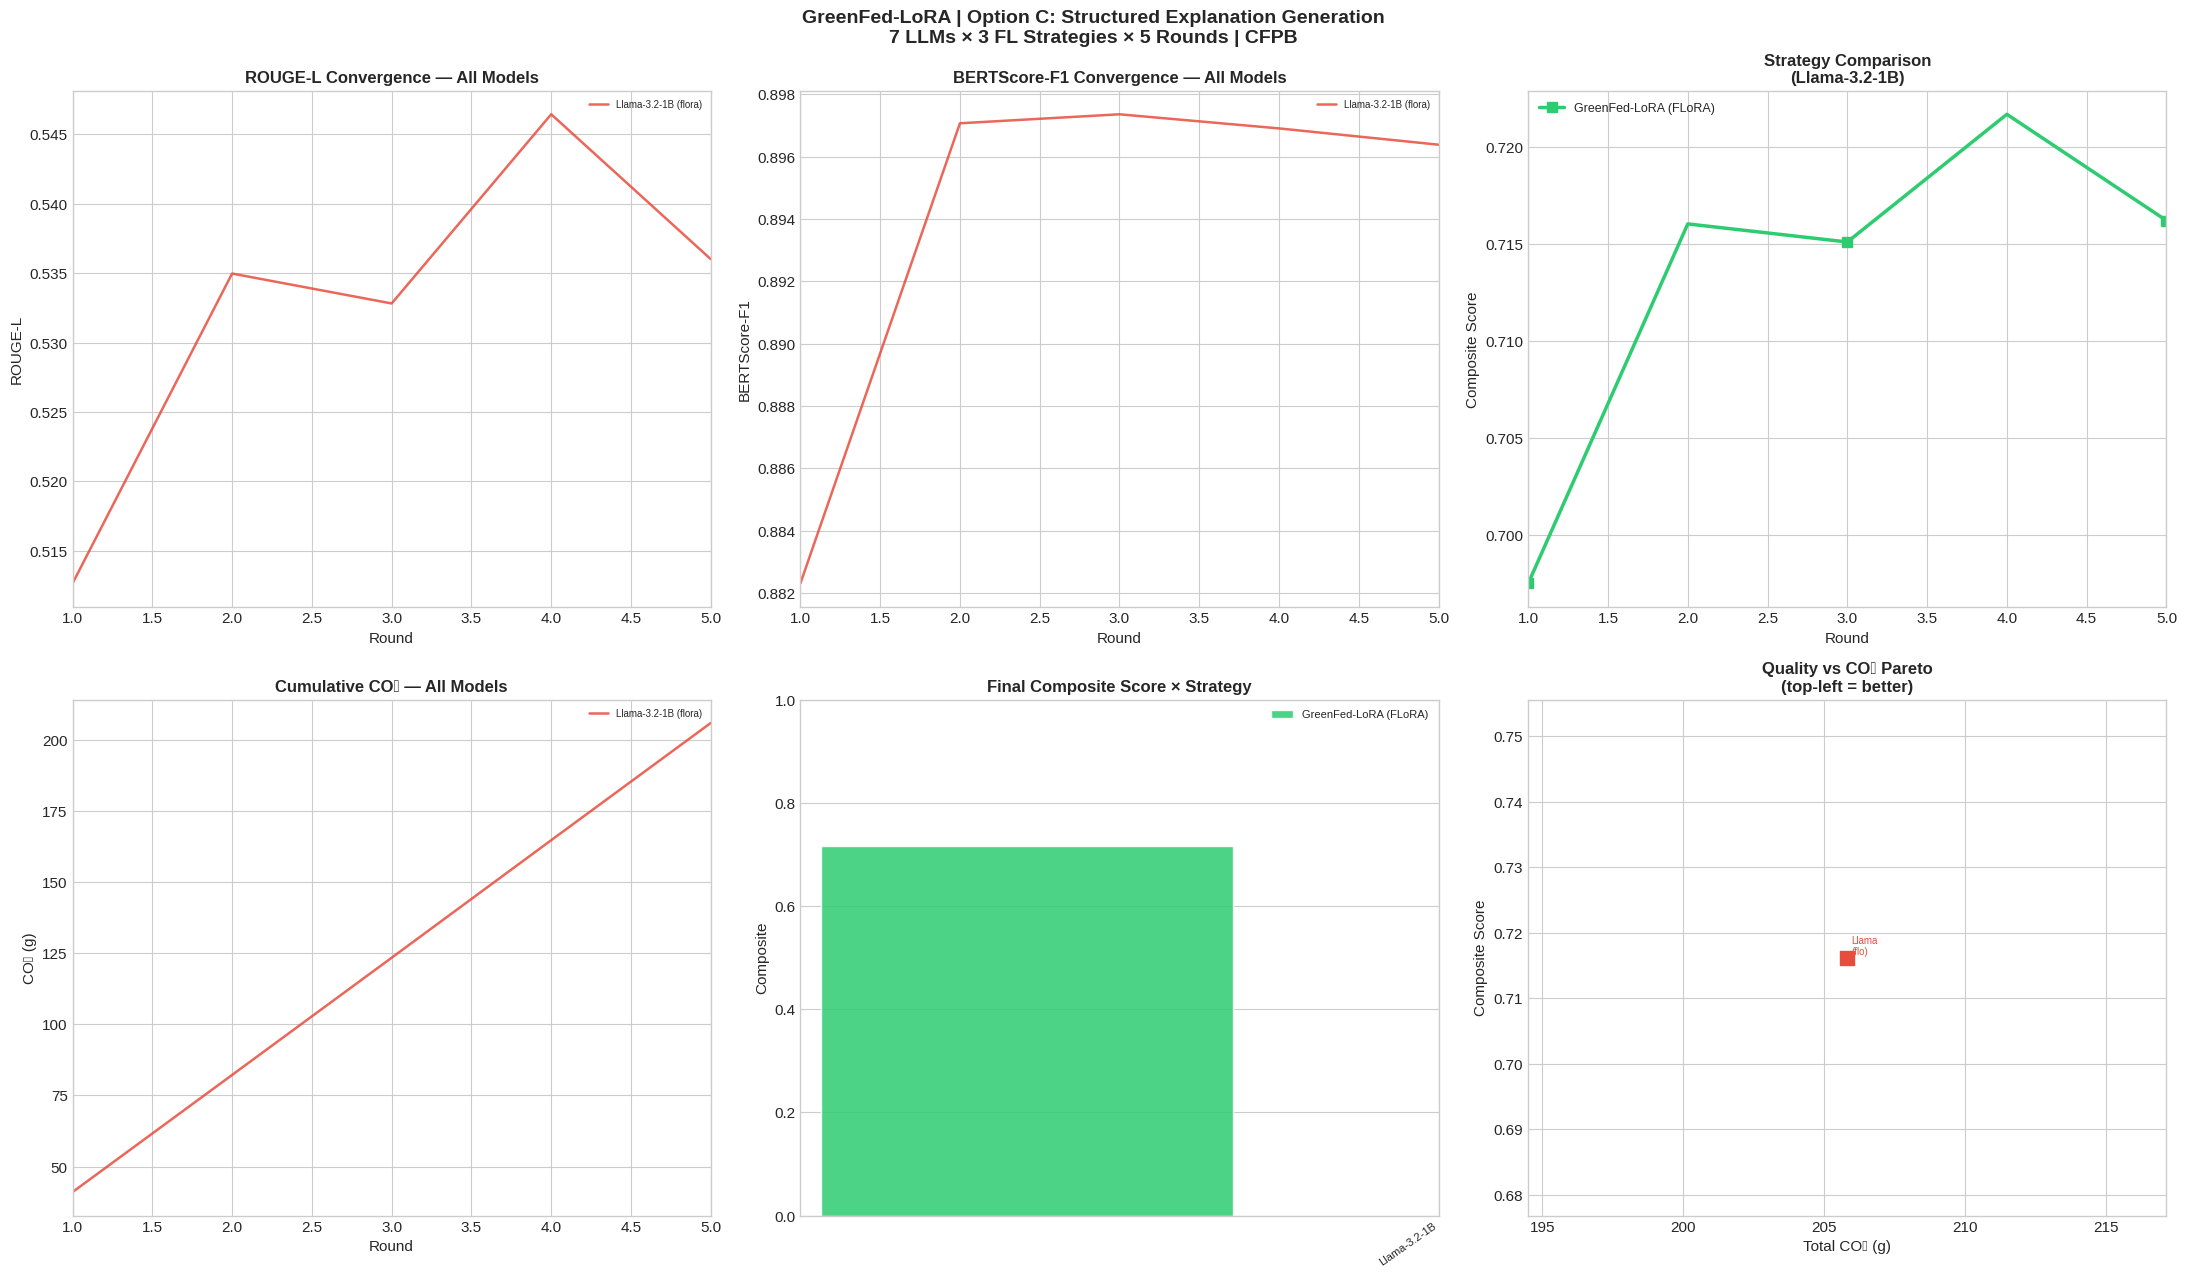

✅ Fig 1: /kaggle/working/greenfed_output/thesis_fig1_convergence.png


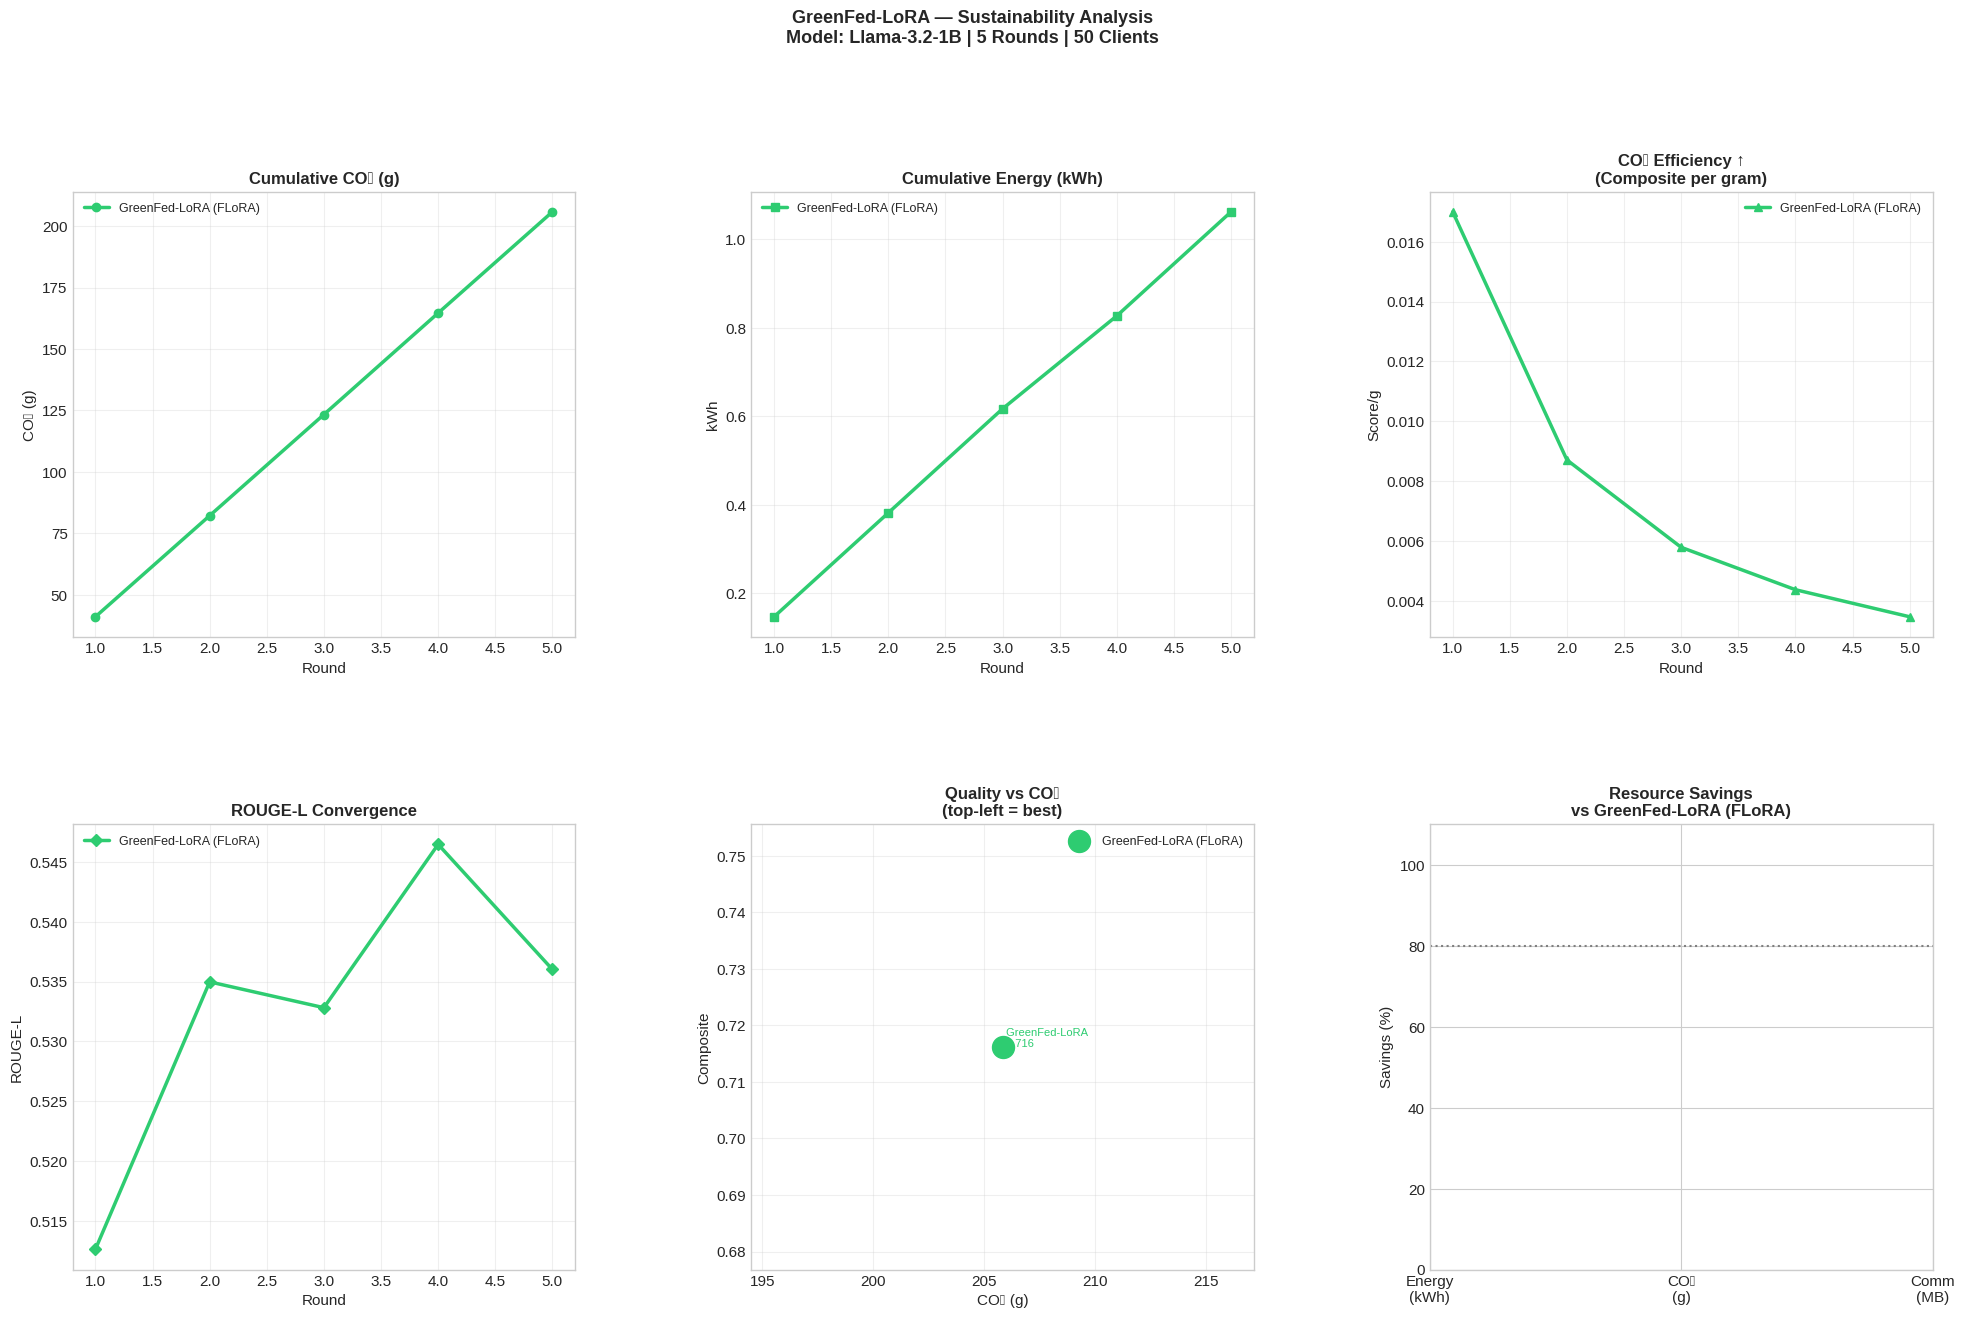

✅ Fig 2: /kaggle/working/greenfed_output/llama32_1b_sustainability.png
⚠ Fig 3 needs ≥2 models complete.


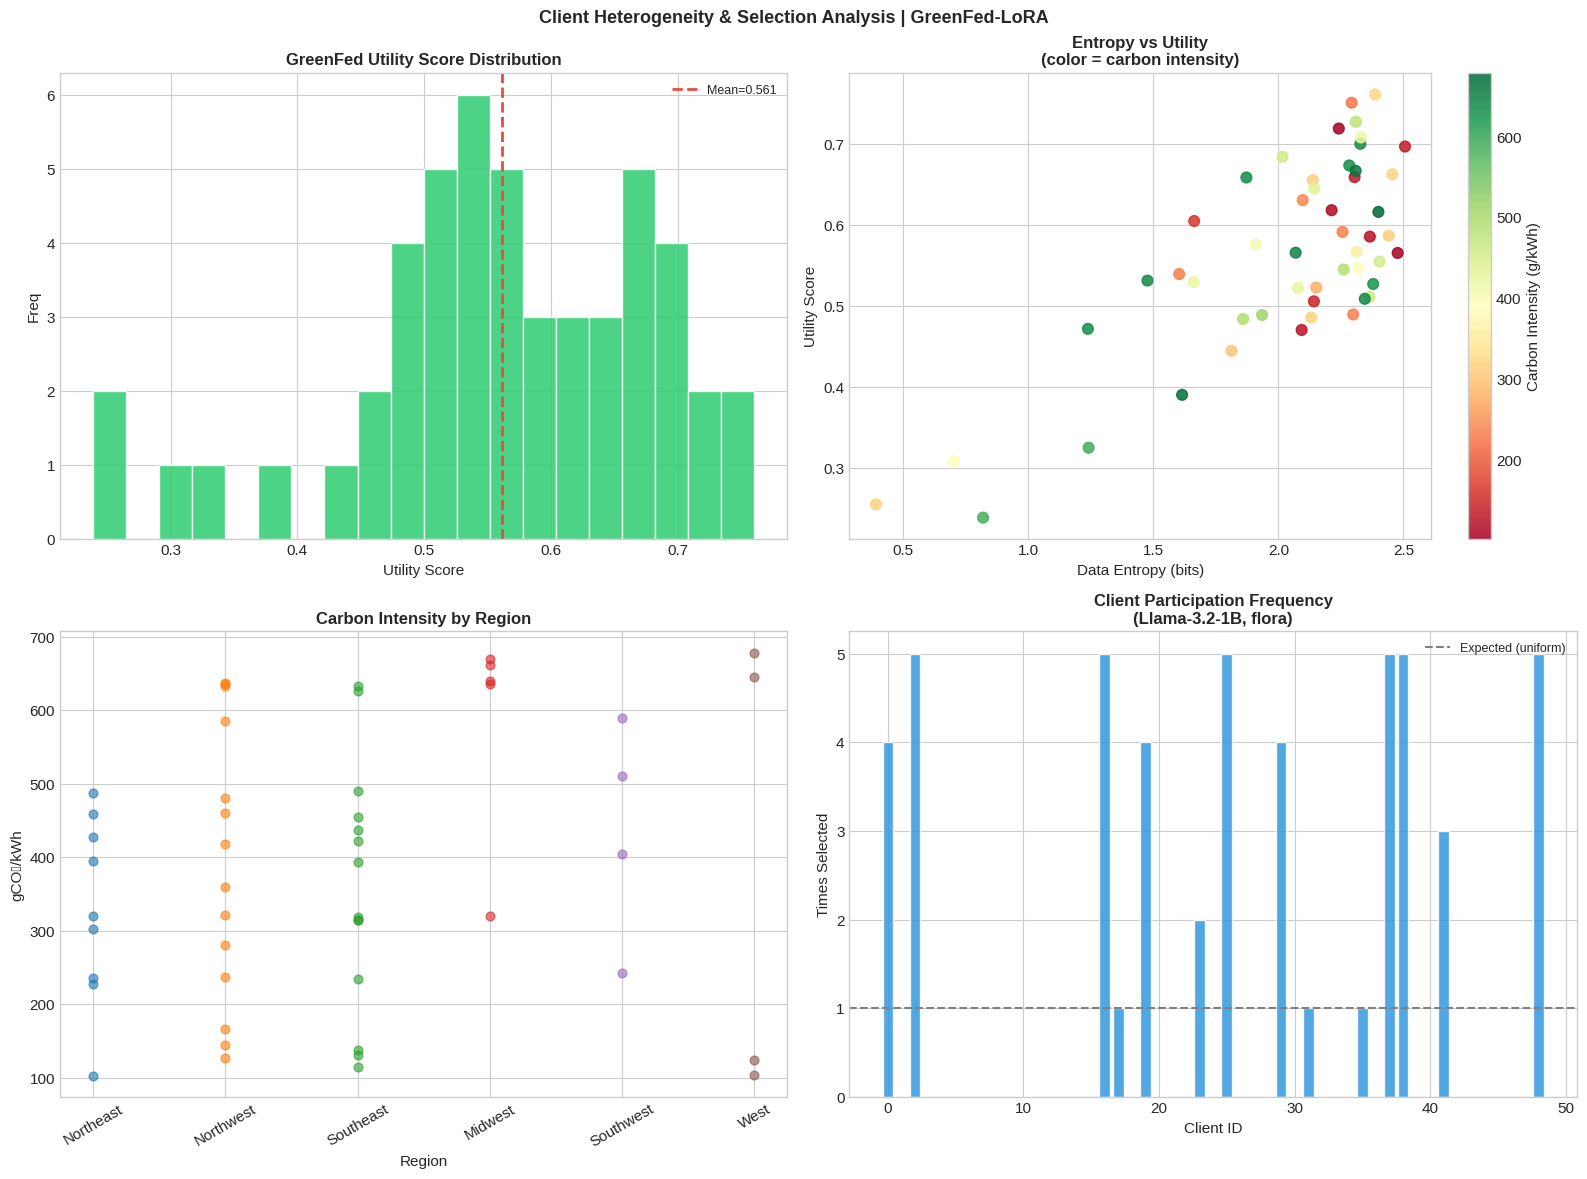

✅ Fig 4: /kaggle/working/greenfed_output/thesis_fig4_client_analysis.png


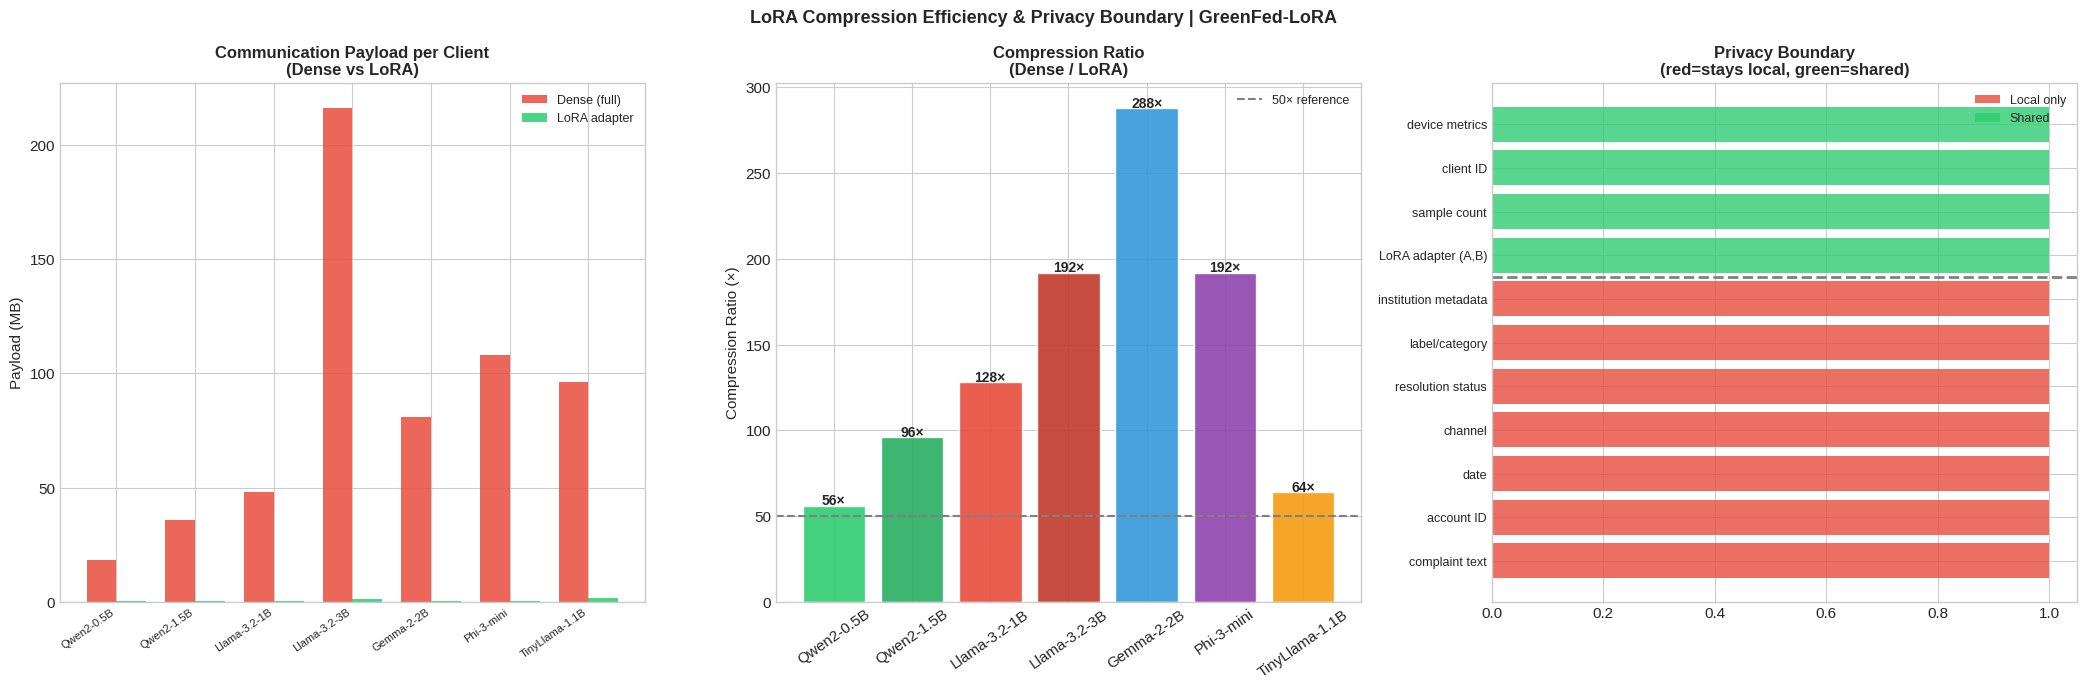

✅ Fig 5: /kaggle/working/greenfed_output/thesis_fig5_lora_privacy.png

════════════════════════════════════════════════════════════════════════════════════════
GreenFed-LoRA | Option C: Structured Explanation Generation | RESULTS SUMMARY
Model                Finetune       Strategy    ROUGE-L  BERTScore  Composite   CO₂(g)     Energy  Comm(MB)
────────────────────────────────────────────────────────────────────────────────────────
Llama-3.2-1B         ffn_only       flora        0.5360     0.8964     0.7162   205.82    1.06224    187.50 ◀ BEST
────────────────────────────────────────────────────────────────────────────────────────

🏆 Best: Llama-3.2-1B (ffn_only, flora) composite=0.7162

Figures → /kaggle/working/greenfed_output/
thesis_fig1_convergence.png   | thesis_fig2_sustainability.png
thesis_fig3_heatmap.png       | thesis_fig4_client_analysis.png
thesis_fig5_lora_privacy.png

Thesis note:
  Encoder (RoBERTa) → classification baseline → macro-F1
  Decoder (LLM)     → generation 

In [19]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  BLOCK 13 — All Thesis Figures (works with partial results)            ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import Counter
 
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size':11,'axes.titlesize':12,'legend.fontsize':9})
 
MC={'qwen2_05b':'#2ecc71','qwen2_15b':'#27ae60','llama32_1b':'#e74c3c',
    'llama32_3b':'#c0392b','gemma2_2b':'#3498db','phi3_mini':'#8e44ad','tinyllama':'#f39c12'}
avail=[c for c in MODEL_REGISTRY if c['session_key'] in all_results and all_results[c['session_key']]]
ROUNDS=list(range(1,NUM_ROUNDS+1))
 
def gv(sk,strat,key,scale=1.0):
    M=all_results.get(sk,{}).get(strat,{})
    v=M.get(key,[])
    return (ROUNDS[:len(v)],[x*scale for x in v])
 
def gf(sk,strat,key,scale=1.0):
    M=all_results.get(sk,{}).get(strat,{})
    v=M.get(key,[0])
    return v[-1]*scale if v else 0.0
 
if not avail:
    print('No results yet — run Block 11 first.')
else:
    # Best model by composite
    best_sk=max([c['session_key'] for c in avail],
                 key=lambda sk:max(all_results[sk].get('flora',
                   all_results[sk].get('fedavg',
                   all_results[sk].get('all',{'composite':[0]}))).get('composite',[0])))
    best_name=next(c['display'] for c in MODEL_REGISTRY if c['session_key']==best_sk)
    best_strats=list(all_results[best_sk].keys())
    print(f'Best model: {best_name} | Available strategies: {best_strats}')
 
    # ════════════════════════════════════════════════════════════════════════
    # FIG 1 — Convergence curves (2×3)
    # ════════════════════════════════════════════════════════════════════════
    fig1,ax1=plt.subplots(2,3,figsize=(22,13))
    fig1.suptitle('GreenFed-LoRA | Option C: Structured Explanation Generation\n'
                  f'7 LLMs × 3 FL Strategies × {NUM_ROUNDS} Rounds | CFPB',
                  fontsize=14,fontweight='bold')
 
    ax=ax1[0][0]
    for cfg in avail:
        sk=cfg['session_key']
        for strat in all_results[sk]:
            xs,ys=gv(sk,strat,'rouge_l')
            if ys: ax.plot(xs,ys,color=MC[sk],
                            ls=STRAT_STYLES[strat]['ls'],lw=1.8,
                            label=f"{cfg['display']} ({strat})",alpha=0.85)
    ax.set_title('ROUGE-L Convergence — All Models',fontweight='bold')
    ax.set_xlabel('Round'); ax.set_ylabel('ROUGE-L')
    ax.legend(fontsize=7,ncol=1 if len(avail)<=3 else 2); ax.set_xlim(1,NUM_ROUNDS)
 
    ax=ax1[0][1]
    for cfg in avail:
        sk=cfg['session_key']
        for strat in all_results[sk]:
            xs,ys=gv(sk,strat,'bert_score')
            if ys: ax.plot(xs,ys,color=MC[sk],
                            ls=STRAT_STYLES[strat]['ls'],lw=1.8,alpha=0.85,
                            label=f"{cfg['display']} ({strat})")
    ax.set_title('BERTScore-F1 Convergence — All Models',fontweight='bold')
    ax.set_xlabel('Round'); ax.set_ylabel('BERTScore-F1')
    ax.legend(fontsize=7,ncol=1 if len(avail)<=3 else 2); ax.set_xlim(1,NUM_ROUNDS)
 
    ax=ax1[0][2]
    for strat in best_strats:
        xs,ys=gv(best_sk,strat,'composite')
        if ys:
            st=STRAT_STYLES[strat]
            ax.plot(xs,ys,color=st['color'],ls=st['ls'],lw=2.5,
                    marker=st['marker'],markevery=2,markersize=7,label=st['label'])
    ax.set_title(f'Strategy Comparison\n({best_name})',fontweight='bold')
    ax.set_xlabel('Round'); ax.set_ylabel('Composite Score')
    ax.legend(); ax.set_xlim(1,NUM_ROUNDS)
 
    ax=ax1[1][0]
    for cfg in avail:
        sk=cfg['session_key']
        for strat in all_results[sk]:
            xs,ys=gv(sk,strat,'co2_kg',1000)
            if ys: ax.plot(xs,ys,color=MC[sk],ls=STRAT_STYLES[strat]['ls'],
                            lw=1.8,alpha=0.85,label=f"{cfg['display']} ({strat})")
    ax.set_title('Cumulative CO₂ — All Models',fontweight='bold')
    ax.set_xlabel('Round'); ax.set_ylabel('CO₂ (g)')
    ax.legend(fontsize=7,ncol=1 if len(avail)<=3 else 2); ax.set_xlim(1,NUM_ROUNDS)
 
    ax=ax1[1][1]
    model_labels=[cfg['display'].replace('-Instruct','') for cfg in avail]
    strats_avail=list({s for c in avail for s in all_results[c['session_key']]})
    x=np.arange(len(avail)); w=0.28
    for si,strat in enumerate(strats_avail):
        vals=[gf(c['session_key'],strat,'composite') for c in avail]
        ax.bar(x+(si-1)*w,vals,w,label=STRAT_STYLES[strat]['label'],
               color=STRAT_STYLES[strat]['color'],alpha=0.85,edgecolor='white')
    ax.set_xticks(x); ax.set_xticklabels(model_labels,rotation=35,ha='right',fontsize=8)
    ax.set_title('Final Composite Score × Strategy',fontweight='bold')
    ax.set_ylabel('Composite'); ax.legend(fontsize=8); ax.set_ylim(0,1.0)
 
    ax=ax1[1][2]
    for cfg in avail:
        sk=cfg['session_key']
        for strat in all_results[sk]:
            comp=gf(sk,strat,'composite'); co2=gf(sk,strat,'co2_kg',1000)
            if comp>0:
                ax.scatter(co2,comp,s=100,color=MC[sk],
                            marker=STRAT_STYLES[strat]['marker'],zorder=5)
                ax.annotate(f"{cfg['display'].split('-')[0]}\n({strat[:3]})",
                             xy=(co2,comp),xytext=(3,2),textcoords='offset points',
                             fontsize=7,color=MC[sk])
    ax.set_title('Quality vs CO₂ Pareto\n(top-left = better)',fontweight='bold')
    ax.set_xlabel('Total CO₂ (g)'); ax.set_ylabel('Composite Score')
 
    plt.tight_layout()
    f1=os.path.join(OUTPUT_DIR,'thesis_fig1_convergence.png')
    plt.savefig(f1,dpi=150,bbox_inches='tight'); plt.show()
    print(f'✅ Fig 1: {f1}')
 
    # ════════════════════════════════════════════════════════════════════════
    # FIG 2 — Sustainability (best model, 2×3)
    # ════════════════════════════════════════════════════════════════════════
    fig2=plt.figure(figsize=(24,14))
    fig2.suptitle(f'GreenFed-LoRA — Sustainability Analysis\n'
                  f'Model: {best_name} | {NUM_ROUNDS} Rounds | {NUM_CLIENTS} Clients',
                  fontsize=13,fontweight='bold',y=1.01)
    gs=gridspec.GridSpec(2,3,figure=fig2,hspace=0.42,wspace=0.35)
 
    # P1: CO₂
    ax1f=fig2.add_subplot(gs[0,0])
    for strat in best_strats:
        xs,ys=gv(best_sk,strat,'co2_kg',1000); st=STRAT_STYLES[strat]
        if ys: ax1f.plot(xs,ys,color=st['color'],ls=st['ls'],lw=2.5,
                          marker='o',markersize=6,label=st['label'])
    ax1f.set_title('Cumulative CO₂ (g)',fontweight='bold')
    ax1f.set_xlabel('Round'); ax1f.set_ylabel('CO₂ (g)'); ax1f.legend(); ax1f.grid(alpha=0.3)
 
    # P2: Energy
    ax2f=fig2.add_subplot(gs[0,1])
    for strat in best_strats:
        xs,ys=gv(best_sk,strat,'energy_kwh'); st=STRAT_STYLES[strat]
        if ys: ax2f.plot(xs,ys,color=st['color'],ls=st['ls'],lw=2.5,
                          marker='s',markersize=6,label=st['label'])
    ax2f.set_title('Cumulative Energy (kWh)',fontweight='bold')
    ax2f.set_xlabel('Round'); ax2f.set_ylabel('kWh'); ax2f.legend(); ax2f.grid(alpha=0.3)
 
    # P3: CO₂ efficiency
    ax3f=fig2.add_subplot(gs[0,2])
    for strat in best_strats:
        M=all_results[best_sk].get(strat,{})
        comp=M.get('composite',[]); co2=[v*1000 for v in M.get('co2_kg',[])]
        eff=[c/g if g>0 else 0 for c,g in zip(comp,co2)]; st=STRAT_STYLES[strat]
        if eff: ax3f.plot(ROUNDS[:len(eff)],eff,color=st['color'],ls=st['ls'],
                           lw=2.5,marker='^',markersize=6,label=st['label'])
    ax3f.set_title('CO₂ Efficiency ↑\n(Composite per gram)',fontweight='bold')
    ax3f.set_xlabel('Round'); ax3f.set_ylabel('Score/g'); ax3f.legend(); ax3f.grid(alpha=0.3)
 
    # P4: ROUGE-L convergence
    ax4f=fig2.add_subplot(gs[1,0])
    for strat in best_strats:
        xs,ys=gv(best_sk,strat,'rouge_l'); st=STRAT_STYLES[strat]
        if ys: ax4f.plot(xs,ys,color=st['color'],ls=st['ls'],lw=2.5,
                          marker='D',markersize=6,label=st['label'])
    ax4f.set_title('ROUGE-L Convergence',fontweight='bold')
    ax4f.set_xlabel('Round'); ax4f.set_ylabel('ROUGE-L'); ax4f.legend(); ax4f.grid(alpha=0.3)
 
    # P5: Pareto
    ax5f=fig2.add_subplot(gs[1,1])
    for strat in best_strats:
        comp=gf(best_sk,strat,'composite'); co2=gf(best_sk,strat,'co2_kg',1000)
        if comp>0:
            ax5f.scatter(co2,comp,s=250,color=STRAT_STYLES[strat]['color'],zorder=5,
                          label=STRAT_STYLES[strat]['label'])
            ax5f.annotate(f" {STRAT_STYLES[strat]['label'][:14]}\n {comp:.3f}",
                           xy=(co2,comp),fontsize=8,color=STRAT_STYLES[strat]['color'])
    ax5f.set_title('Quality vs CO₂\n(top-left = best)',fontweight='bold')
    ax5f.set_xlabel('CO₂ (g)'); ax5f.set_ylabel('Composite'); ax5f.legend(); ax5f.grid(alpha=0.3)
 
    # P6: Savings bars
    ax6f=fig2.add_subplot(gs[1,2])
    base_strat='all' if 'all' in best_strats else best_strats[-1]
    be=gf(best_sk,base_strat,'energy_kwh') or 1e-8
    bc=gf(best_sk,base_strat,'co2_kg',1000) or 1e-8
    bm=gf(best_sk,base_strat,'comm_mb') or 1e-8
    compare=['flora','fedavg'] if len(best_strats)>1 else best_strats
    xx=np.arange(3); width=0.35
    for si,strat in enumerate([s for s in compare if s!=base_strat][:2]):
        sv=[100*(1-gf(best_sk,strat,k,sc)/(ref+1e-10))
            for k,sc,ref in [('energy_kwh',1.0,be),('co2_kg',1000,bc),('comm_mb',1.0,bm)]]
        b=ax6f.bar(xx+(si-0.5)*width,sv,width,color=STRAT_STYLES[strat]['color'],
                    label=STRAT_STYLES[strat]['label'],alpha=0.9)
        for bar in b:
            ax6f.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.5,
                       f'{bar.get_height():.1f}%',ha='center',fontsize=9,fontweight='bold')
    ax6f.set_xticks(xx); ax6f.set_xticklabels(['Energy\n(kWh)','CO₂\n(g)','Comm\n(MB)'])
    ax6f.set_title(f'Resource Savings\nvs {STRAT_STYLES[base_strat]["label"]}',fontweight='bold')
    ax6f.set_ylabel('Savings (%)'); ax6f.set_ylim(0,110)
    ax6f.axhline(80,color='gray',ls=':',lw=1.5); ax6f.legend()
 
    fig2.tight_layout()
    f2=os.path.join(OUTPUT_DIR,f'{best_sk}_sustainability.png')
    plt.savefig(f2,dpi=150,bbox_inches='tight'); plt.show()
    print(f'✅ Fig 2: {f2}')
 
    # ════════════════════════════════════════════════════════════════════════
    # FIG 3 — Heatmaps (needs ≥2 models)
    # ════════════════════════════════════════════════════════════════════════
    if len(avail) >= 2:
        sks_av=[c['session_key'] for c in avail]
        all_strats=sorted({s for sk in sks_av for s in all_results[sk]})
        ml=[f"{c['display'].replace('-Instruct','')}\n({c['finetune']})" for c in avail]
        xl=[STRAT_STYLES[s]['label'][:14] for s in all_strats]
 
        rm=np.array([[gf(sk,s,'rouge_l')      for s in all_strats] for sk in sks_av])
        bm=np.array([[gf(sk,s,'bert_score')    for s in all_strats] for sk in sks_av])
        cm_=np.array([[gf(sk,s,'co2_kg',1000)  for s in all_strats] for sk in sks_av])
 
        fig3,ax3=plt.subplots(1,3,figsize=(20,max(5,len(avail)+2)))
        fig3.suptitle(f'Fine-Tuning Strategy Ablation | {len(avail)} LLMs × {len(all_strats)} Strategies',
                       fontsize=13,fontweight='bold')
        for axi,mat,cmap,title,fmt in [(ax3[0],rm,'YlGn','ROUGE-L','.3f'),
                                         (ax3[1],bm,'Blues','BERTScore-F1','.3f'),
                                         (ax3[2],cm_,'Reds_r','Total CO₂ (g) ↓','.2f')]:
            sns.heatmap(mat,annot=True,fmt=fmt,cmap=cmap,
                         xticklabels=xl,yticklabels=ml,ax=axi,
                         cbar_kws={'label':title})
            axi.set_title(title,fontweight='bold')
        plt.tight_layout()
        f3=os.path.join(OUTPUT_DIR,'thesis_fig3_heatmap.png')
        plt.savefig(f3,dpi=150,bbox_inches='tight'); plt.show()
        print(f'✅ Fig 3: {f3}')
    else:
        print('⚠ Fig 3 needs ≥2 models complete.')
 
    # ════════════════════════════════════════════════════════════════════════
    # FIG 4 — Client Diversity + Selection Analysis (2×2)
    # ════════════════════════════════════════════════════════════════════════
    fig4,ax4=plt.subplots(2,2,figsize=(16,12))
    fig4.suptitle('Client Heterogeneity & Selection Analysis | GreenFed-LoRA',
                   fontsize=13,fontweight='bold')
 
    ax4[0][0].hist(stats_df['utility_score'],bins=20,color='#2ecc71',alpha=0.85,edgecolor='w')
    ax4[0][0].axvline(stats_df['utility_score'].mean(),color='#e74c3c',ls='--',lw=2,
                       label=f"Mean={stats_df['utility_score'].mean():.3f}")
    ax4[0][0].set_title('GreenFed Utility Score Distribution',fontweight='bold')
    ax4[0][0].set_xlabel('Utility Score'); ax4[0][0].set_ylabel('Freq'); ax4[0][0].legend()
 
    sc=ax4[0][1].scatter(stats_df['entropy'],stats_df['utility_score'],
                          c=stats_df['carbon_intensity'],cmap='RdYlGn',s=60,alpha=0.85)
    plt.colorbar(sc,ax=ax4[0][1],label='Carbon Intensity (g/kWh)')
    ax4[0][1].set_title('Entropy vs Utility\n(color = carbon intensity)',fontweight='bold')
    ax4[0][1].set_xlabel('Data Entropy (bits)'); ax4[0][1].set_ylabel('Utility Score')
 
    for rg in stats_df['region'].unique():
        sub=stats_df[stats_df['region']==rg]['carbon_intensity']
        ax4[1][0].scatter([rg]*len(sub),sub,alpha=0.6,s=40)
    ax4[1][0].set_title('Carbon Intensity by Region',fontweight='bold')
    ax4[1][0].set_xlabel('Region'); ax4[1][0].set_ylabel('gCO₂/kWh')
    ax4[1][0].tick_params(axis='x',rotation=30)
 
    strat_for_hist = next((s for s in ['flora','fedavg','all']
                            if all_results.get(best_sk,{}).get(s,{}).get('selected_history')), None)
    if strat_for_hist:
        hist=all_results[best_sk][strat_for_hist]['selected_history']
        cnt=Counter([c for r in hist for c in r])
        cids=sorted(cnt.keys()); vals=[cnt.get(c,0) for c in cids]
        ax4[1][1].bar(cids,vals,color='#3498db',alpha=0.85,width=0.8,edgecolor='w')
        ax4[1][1].set_title(f'Client Participation Frequency\n({best_name}, {strat_for_hist})',fontweight='bold')
        ax4[1][1].set_xlabel('Client ID'); ax4[1][1].set_ylabel('Times Selected')
        ax4[1][1].axhline(CLIENTS_PER_ROUND_UTIL*NUM_ROUNDS/NUM_CLIENTS,
                           color='gray',ls='--',lw=1.5,label='Expected (uniform)')
        ax4[1][1].legend()
    else:
        ax4[1][1].text(0.5,0.5,'No participation data yet',ha='center',va='center',
                        transform=ax4[1][1].transAxes)
 
    plt.tight_layout()
    f4=os.path.join(OUTPUT_DIR,'thesis_fig4_client_analysis.png')
    plt.savefig(f4,dpi=150,bbox_inches='tight'); plt.show()
    print(f'✅ Fig 4: {f4}')
 
    # ════════════════════════════════════════════════════════════════════════
    # FIG 5 — LoRA Compression + Privacy (1×3)
    # ════════════════════════════════════════════════════════════════════════
    fig5,ax5=plt.subplots(1,3,figsize=(21,7))
    fig5.suptitle('LoRA Compression Efficiency & Privacy Boundary | GreenFed-LoRA',
                   fontsize=13,fontweight='bold')
 
    HIDDEN={'qwen2_05b':896,'qwen2_15b':1536,'llama32_1b':2048,'llama32_3b':3072,
            'gemma2_2b':2304,'phi3_mini':3072,'tinyllama':2048}
    m_names,lora_kbs,dense_kbs,ratios=[],[],[],[]
    for cfg in MODEL_REGISTRY:
        h=HIDDEN.get(cfg['session_key'],1024); r=cfg['lora_r']; nt=len(cfg['lora_targets'])
        lkb=2*r*h*nt*4/1024; dkb=h*h*nt*4/1024
        m_names.append(cfg['display'].replace('-Instruct',''))
        lora_kbs.append(lkb/1024); dense_kbs.append(dkb/1024); ratios.append(dkb/lkb)
 
    xx=np.arange(len(m_names)); ww=0.38
    ax5[0].bar(xx-ww/2,[d for d in dense_kbs],ww,label='Dense (full)',color='#e74c3c',alpha=0.85)
    ax5[0].bar(xx+ww/2,[l for l in lora_kbs], ww,label='LoRA adapter',color='#2ecc71',alpha=0.85)
    ax5[0].set_xticks(xx); ax5[0].set_xticklabels(m_names,rotation=35,ha='right',fontsize=8)
    ax5[0].set_title('Communication Payload per Client\n(Dense vs LoRA)',fontweight='bold')
    ax5[0].set_ylabel('Payload (MB)'); ax5[0].legend()
 
    bars=ax5[1].bar(m_names,ratios,
                     color=[MC.get(c['session_key'],'#aaa') for c in MODEL_REGISTRY],
                     alpha=0.9,edgecolor='w')
    for bar,v in zip(bars,ratios):
        ax5[1].text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.5,
                     f'{v:.0f}×',ha='center',fontsize=10,fontweight='bold')
    ax5[1].set_title('Compression Ratio\n(Dense / LoRA)',fontweight='bold')
    ax5[1].set_ylabel('Compression Ratio (×)')
    ax5[1].axhline(50,color='gray',ls='--',lw=1.5,label='50× reference')
    ax5[1].legend(); ax5[1].tick_params(axis='x',rotation=35)
 
    LOCAL=['complaint text','account ID','date','channel',
           'resolution status','label/category','institution metadata']
    SHARED=['LoRA adapter (A,B)','sample count','client ID','device metrics']
    ax5[2].barh(range(len(LOCAL)),[1]*len(LOCAL),color='#e74c3c',alpha=0.8,label='Local only')
    ax5[2].barh(range(len(LOCAL),len(LOCAL)+len(SHARED)),[1]*len(SHARED),
                 color='#2ecc71',alpha=0.8,label='Shared')
    ax5[2].set_yticks(range(len(LOCAL)+len(SHARED)))
    ax5[2].set_yticklabels(LOCAL+SHARED,fontsize=9)
    ax5[2].axhline(len(LOCAL)-0.5,color='gray',ls='--',lw=2)
    ax5[2].set_title('Privacy Boundary\n(red=stays local, green=shared)',fontweight='bold')
    ax5[2].legend()
 
    plt.tight_layout()
    f5=os.path.join(OUTPUT_DIR,'thesis_fig5_lora_privacy.png')
    plt.savefig(f5,dpi=150,bbox_inches='tight'); plt.show()
    print(f'✅ Fig 5: {f5}')
 
    # ════════════════════════════════════════════════════════════════════════
    # FINAL SUMMARY TABLE
    # ════════════════════════════════════════════════════════════════════════
    print('\n'+'═'*88)
    print('GreenFed-LoRA | Option C: Structured Explanation Generation | RESULTS SUMMARY')
    print('='*88)
    print(f'{"Model":<20} {"Finetune":<14} {"Strategy":<10} '
          f'{"ROUGE-L":>8} {"BERTScore":>10} {"Composite":>10} '
          f'{"CO₂(g)":>8} {"Energy":>10} {"Comm(MB)":>9}')
    print('─'*88)
    best_comp=0; best_row=None
    for cfg in MODEL_REGISTRY:
        sk=cfg['session_key']
        if sk not in all_results: continue
        for strat,M in all_results[sk].items():
            if not M.get('rouge_l'): continue
            rl=M['rouge_l'][-1]; bs=M['bert_score'][-1]; cp=M['composite'][-1]
            en=M['energy_kwh'][-1]; co=M['co2_kg'][-1]*1000; cm_=M['comm_mb'][-1]
            tag=' ◀ BEST' if cp>best_comp else ''
            if cp>best_comp: best_comp=cp; best_row=(cfg['display'],cfg['finetune'],strat,cp)
            print(f"{cfg['display']:<20} {cfg['finetune']:<14} {strat:<10} "
                  f"{rl:>8.4f} {bs:>10.4f} {cp:>10.4f} "
                  f"{co:>8.2f} {en:>10.5f} {cm_:>9.2f}{tag}")
    print('─'*88)
    if best_row:
        print(f'\n🏆 Best: {best_row[0]} ({best_row[1]}, {best_row[2]}) '
              f'composite={best_row[3]:.4f}')
    print(f'\nFigures → {OUTPUT_DIR}/')
    print('thesis_fig1_convergence.png   | thesis_fig2_sustainability.png')
    print('thesis_fig3_heatmap.png       | thesis_fig4_client_analysis.png')
    print('thesis_fig5_lora_privacy.png')
    print(f'\nThesis note:')
    print('  Encoder (RoBERTa) → classification baseline → macro-F1')
    print('  Decoder (LLM)     → generation task → ROUGE-L + BERTScore')
    print('  Green metrics     → identical FL framework → direct comparison')